In [ ]:
# Repo bootstrap: notebooks use paths relative to the repo root and import from src/
import os, sys
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "pipeline.py").exists())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

# Low Density Evaluation — DINO / Sliding Window

- patches carrés
- fenêtre glissante avec stride 50% pour chaque taille de patch
- grille nominale 4x4 -> 7 positions par ligne
- grille nominale 8x8 -> 15 positions par ligne
- grille nominale 16x16 -> 31 positions par ligne
- recherche automatique des checkpoints dans `./runs/`
- génération cartes de densité / probabilité


In [42]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image

import matplotlib.pyplot as plt
import matplotlib.patches as patches

import torch
import torch.nn as nn
from torchvision import transforms

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

In [43]:
LOW_DIR = Path("data/low_density")
IMAGES_DIR = LOW_DIR / "images"
ANNOTATIONS_CSV = LOW_DIR / "annotations.csv"

PATCH_GRID_SIZE = 8
PATCHES_ROOT = LOW_DIR / f"patches_grid{PATCH_GRID_SIZE}_stride50"
PATCH_INDEX_CSV = LOW_DIR / f"patch_index_grid{PATCH_GRID_SIZE}_stride50.csv"
RESULTS_DIR = LOW_DIR / "results"

RUNS_DIR = Path("./runs")


In [44]:
print("DEVICE:", DEVICE)


DEVICE: cpu


## Dataset low density

In [45]:
low_density_df = pd.read_csv(ANNOTATIONS_CSV)

print("Nb annotations:", len(low_density_df))
print("Nb images:", low_density_df["filename"].nunique())

display(low_density_df.head())


Nb annotations: 3406
Nb images: 6


,filename,xmin,ymin,xmax,ymax,geometry,label,source,Unnamed: 0,existing_split,...,tile_name,metadata,treeID,Z,complete,basename,remove,image_path,annotator,split
0,Pfinztal_7.png,201.0,235.0,211.0,243.0,"POLYGON ((211 235, 211 243, 201 243, 201 235, ...",Tree,Weecology_University_Florida,NaN,NaN,...,NaN,NaN,NaN,NaN,True,Pfinztal_7.png,NaN,NaN,NaN,test
1,Pfinztal_7.png,270.0,59.0,273.0,62.0,"POLYGON ((273 59, 273 62, 270 62, 270 59, 273 ...",Tree,Weecology_University_Florida,NaN,NaN,...,NaN,NaN,NaN,NaN,True,Pfinztal_7.png,NaN,NaN,NaN,test
2,Pfinztal_7.png,274.0,53.0,278.0,57.0,"POLYGON ((278 53, 278 57, 274 57, 274 53, 278 ...",Tree,Weecology_University_Florida,NaN,NaN,...,NaN,NaN,NaN,NaN,True,Pfinztal_7.png,NaN,NaN,NaN,test
3,Pfinztal_7.png,310.0,49.0,314.0,55.0,"POLYGON ((314 49, 314 55, 310 55, 310 49, 314 ...",Tree,Weecology_University_Florida,NaN,NaN,...,NaN,NaN,NaN,NaN,True,Pfinztal_7.png,NaN,NaN,NaN,test
4,Pfinztal_7.png,315.0,95.0,319.0,99.0,"POLYGON ((319 95, 319 99, 315 99, 315 95, 319 ...",Tree,Weecology_University_Florida,NaN,NaN,...,NaN,NaN,NaN,NaN,True,Pfinztal_7.png,NaN,NaN,NaN,test


## Visualisation GT

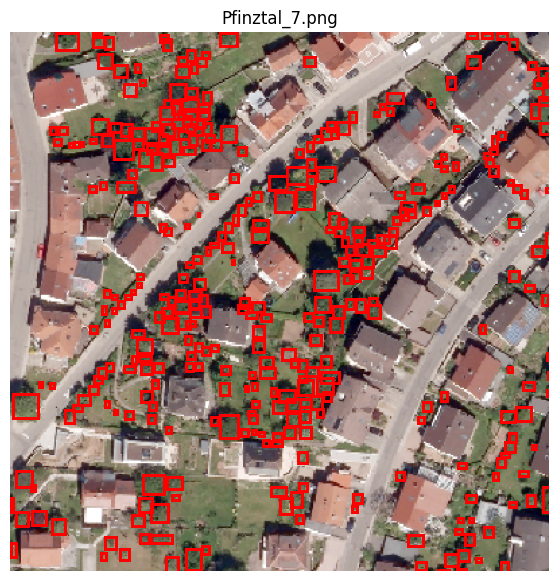

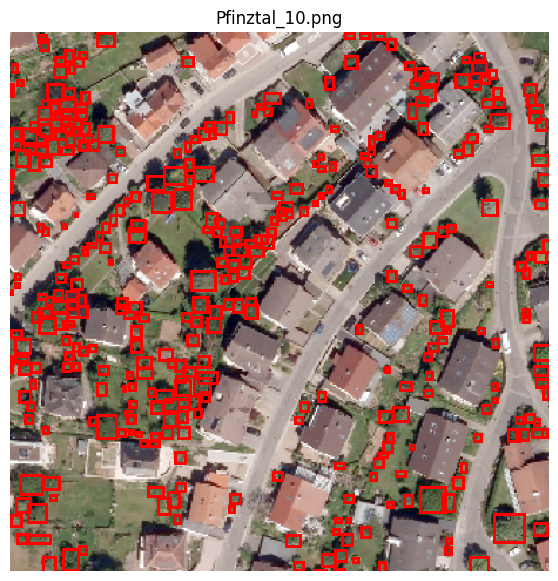

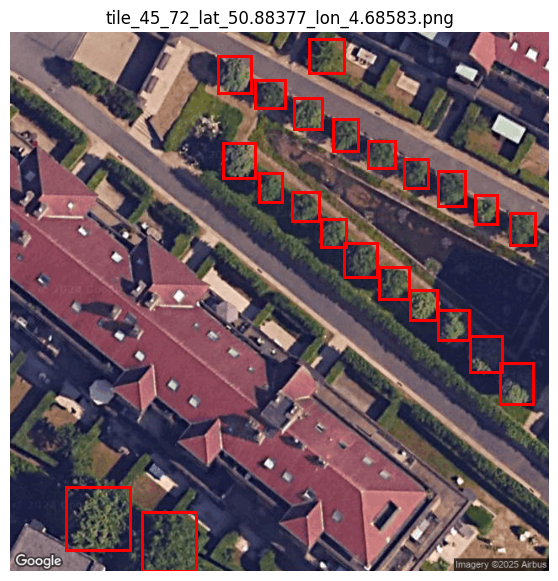

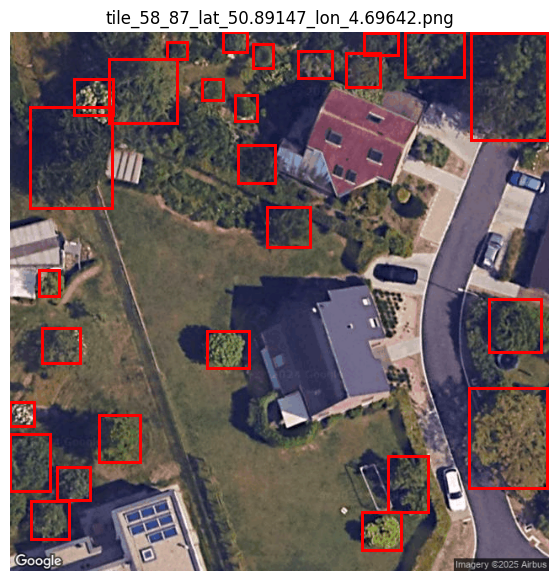

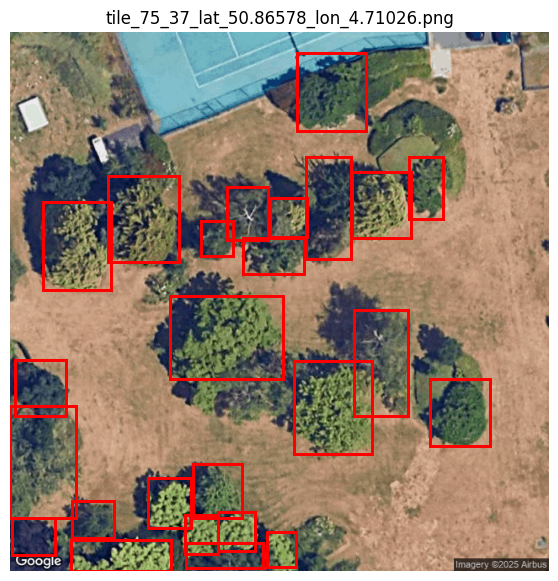

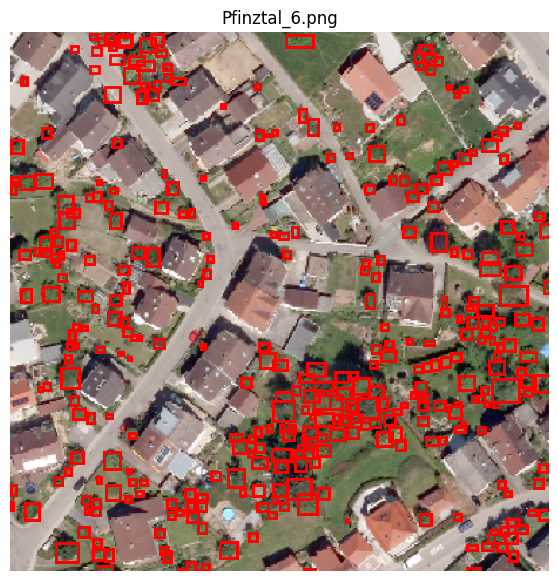

In [5]:
def show_gt(filename):

    img_path = IMAGES_DIR / filename
    img = np.array(Image.open(img_path).convert("RGB"))

    rows = low_density_df[low_density_df["filename"] == filename]

    fig, ax = plt.subplots(figsize=(7,7))
    ax.imshow(img)

    for _, row in rows.iterrows():

        xmin, ymin, xmax, ymax = map(
            float,
            [row["xmin"], row["ymin"], row["xmax"], row["ymax"]]
        )

        rect = patches.Rectangle(
            (xmin, ymin),
            xmax - xmin,
            ymax - ymin,
            linewidth=2,
            edgecolor="red",
            facecolor="none"
        )

        ax.add_patch(rect)

    ax.set_title(filename)
    ax.axis("off")
    plt.show()


for filename in low_density_df["filename"].unique():
    show_gt(filename)


## Choix automatique du patch size

In [6]:
def get_patch_size(width, height, grid_size=PATCH_GRID_SIZE):
    if width != height:
        raise ValueError(
            f"Expected square image, got width={width}, height={height}"
        )

    if width % grid_size != 0:
        raise ValueError(
            f"Image size {width} is not divisible by grid_size={grid_size}"
        )

    return width // grid_size


## Création des patches — DOUBLE BOUCLE

In [7]:
def generate_positions(size, patch_size, grid_size=PATCH_GRID_SIZE):

    n_positions = 2 * grid_size - 1
    positions = np.rint(
        np.linspace(
            0,
            size - patch_size,
            n_positions
        )
    ).astype(int).tolist()

    if len(set(positions)) != n_positions:
        raise ValueError(
            f"Positions dupliquees pour size={size}, patch_size={patch_size}, grid_size={grid_size}"
        )

    return positions


def create_patches():

    PATCHES_ROOT.mkdir(parents=True, exist_ok=True)

    rows = []

    for filename in low_density_df["filename"].unique():

        img_path = IMAGES_DIR / filename
        img = Image.open(img_path).convert("RGB")

        W, H = img.size

        patch_size = get_patch_size(W, H)
        stride = patch_size / 2

        image_stem = Path(filename).stem

        image_patch_dir = PATCHES_ROOT / image_stem
        image_patch_dir.mkdir(parents=True, exist_ok=True)

        xs = generate_positions(W, patch_size)
        ys = generate_positions(H, patch_size)

        patch_id = 0

        # DOUBLE BOUCLE
        # i = ligne
        for i, y in enumerate(ys):

            # j = patch dans ligne
            for j, x in enumerate(xs):

                patch = img.crop(
                    (
                        x,
                        y,
                        x + patch_size,
                        y + patch_size
                    )
                )

                patch_name = (
                    f"patch_i{i:02d}_j{j:02d}"
                    f"_x{x:04d}_y{y:04d}.png"
                )

                patch_path = image_patch_dir / patch_name

                patch.save(patch_path)

                rows.append({
                    "filename": filename,
                    "patch_path": str(patch_path),
                    "patch_id": patch_id,
                    "i": i,
                    "j": j,
                    "x": x,
                    "y": y,
                    "patch_size": patch_size,
                    "stride": stride,
                    "grid_size": PATCH_GRID_SIZE,
                    "n_positions_x": len(xs),
                    "n_positions_y": len(ys),
                    "image_width": W,
                    "image_height": H
                })

                patch_id += 1

        print(
            filename,
            "->",
            patch_id,
            "patches | first row =",
            len(xs),
            "| patch_size =",
            patch_size,
            "| stride =",
            stride,
        )

    patch_df = pd.DataFrame(rows)

    patch_df.to_csv(
        PATCH_INDEX_CSV,
        index=False
    )

    return patch_df


patch_df = create_patches()

print("Saved:", PATCH_INDEX_CSV)
display(patch_df.head())


Pfinztal_7.png -> 225 patches | first row = 15 | patch_size = 50 | stride = 25.0
Pfinztal_10.png -> 225 patches | first row = 15 | patch_size = 50 | stride = 25.0
tile_45_72_lat_50.88377_lon_4.68583.png -> 225 patches | first row = 15 | patch_size = 80 | stride = 40.0
tile_58_87_lat_50.89147_lon_4.69642.png -> 225 patches | first row = 15 | patch_size = 80 | stride = 40.0
tile_75_37_lat_50.86578_lon_4.71026.png -> 225 patches | first row = 15 | patch_size = 80 | stride = 40.0
Pfinztal_6.png -> 225 patches | first row = 15 | patch_size = 50 | stride = 25.0
Saved: data/low_density/patch_index_grid8_stride50.csv


,filename,patch_path,patch_id,i,j,x,y,patch_size,stride,grid_size,n_positions_x,n_positions_y,image_width,image_height
0,Pfinztal_7.png,data/low_density/patches_grid8_stride50/Pfinzt...,0,0,0,0,0,50,25.0,8,15,15,400,400
1,Pfinztal_7.png,data/low_density/patches_grid8_stride50/Pfinzt...,1,0,1,25,0,50,25.0,8,15,15,400,400
2,Pfinztal_7.png,data/low_density/patches_grid8_stride50/Pfinzt...,2,0,2,50,0,50,25.0,8,15,15,400,400
3,Pfinztal_7.png,data/low_density/patches_grid8_stride50/Pfinzt...,3,0,3,75,0,50,25.0,8,15,15,400,400
4,Pfinztal_7.png,data/low_density/patches_grid8_stride50/Pfinzt...,4,0,4,100,0,50,25.0,8,15,15,400,400


## Visualisation grille

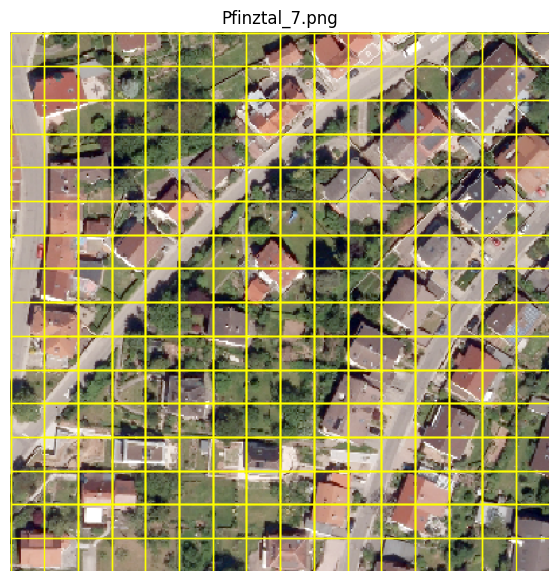

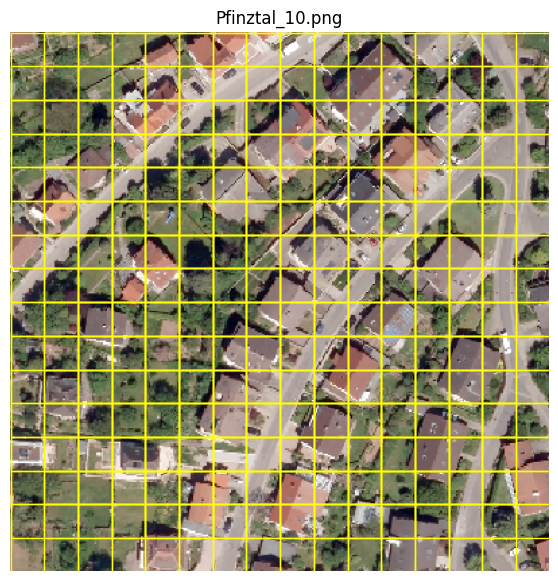

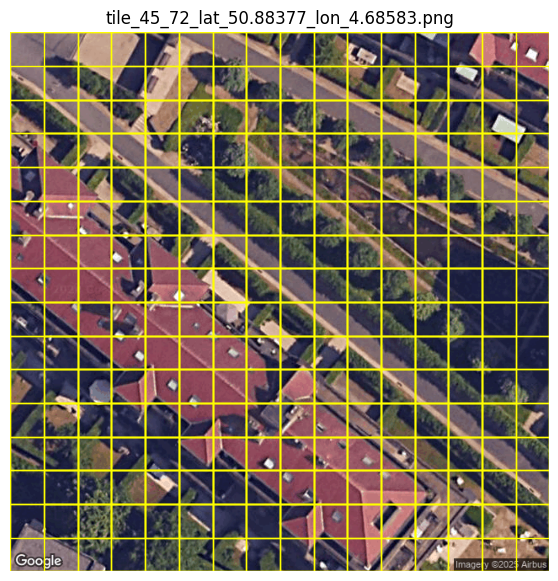

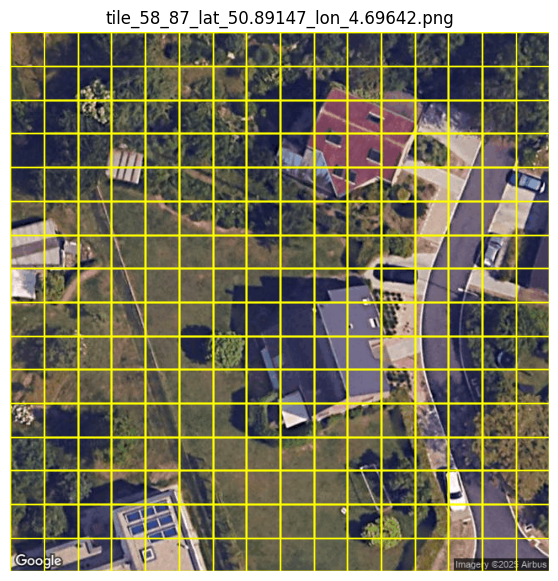

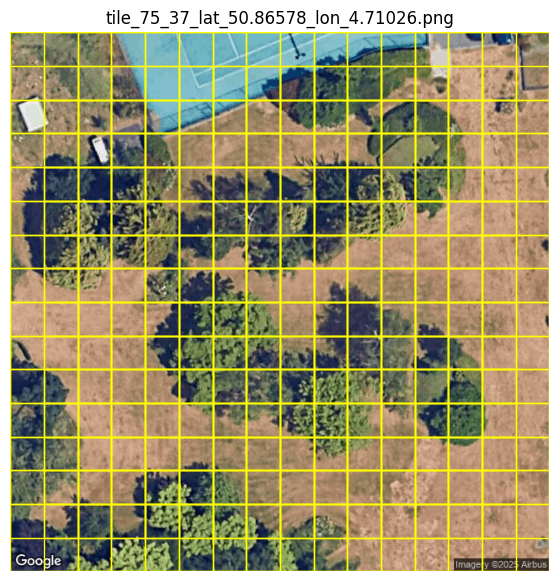

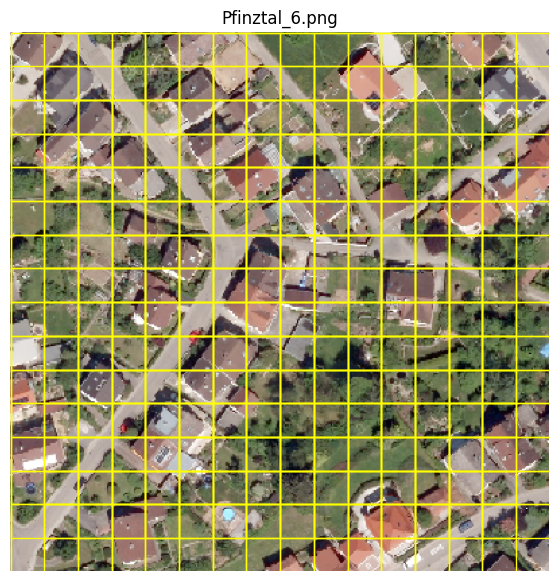

In [8]:
def show_patch_grid(filename):

    img_path = IMAGES_DIR / filename
    img = np.array(Image.open(img_path).convert("RGB"))

    rows = patch_df[patch_df["filename"] == filename]

    fig, ax = plt.subplots(figsize=(7,7))
    ax.imshow(img)

    for _, row in rows.iterrows():

        rect = patches.Rectangle(
            (row["x"], row["y"]),
            row["patch_size"],
            row["patch_size"],
            linewidth=1,
            edgecolor="yellow",
            facecolor="none"
        )

        ax.add_patch(rect)

    ax.set_title(filename)
    ax.axis("off")
    plt.show()


for filename in patch_df["filename"].unique():
    show_patch_grid(filename)


## Recherche automatique checkpoints dans ./runs/

In [9]:
def find_checkpoint_in_run(run_dir):

    # priorité 1
    model_final = list(run_dir.rglob("model_final*.pth"))

    if len(model_final) > 0:
        return model_final[0]

    # priorité 2
    best_models = list(run_dir.rglob("best_model*.pth"))

    if len(best_models) > 0:
        return best_models[0]

    # priorité 3
    best_plain = list(run_dir.rglob("best_model.pth"))

    if len(best_plain) > 0:
        return best_plain[0]

    return None


def discover_models(runs_dir=RUNS_DIR):

    discovered = {}

    for subdir in runs_dir.iterdir():

        if not subdir.is_dir():
            continue

        ckpt = find_checkpoint_in_run(subdir)

        if ckpt is None:

            print(f"[NO CKPT FOUND] {subdir.name}")

        else:

            print(f"[FOUND] {subdir.name} : {ckpt}")

            discovered[subdir.name] = ckpt

    return discovered


discovered_models = discover_models()


[NO CKPT FOUND] vit_v4_seed42_aug
[NO CKPT FOUND] cnn_boxes_v4_augmented
[FOUND] cnn_boxes_v3_normal : runs/cnn_boxes_v3_normal/best_model_SimpleCNN3_0.001_10.pth
[NO CKPT FOUND] resnet18_ft_seed42_aug_v4
[FOUND] dinov2_segmentation : runs/dinov2_segmentation/best_model_dinov2_segmentation.pth
[FOUND] cnn_boxes_v3_augmented : runs/cnn_boxes_v3_augmented/best_model_SimpleCNN3_None_10.pth
[NO CKPT FOUND] resnet18_ft_seed42_aug
[NO CKPT FOUND] resnet18_ft_seed42
[FOUND] dinov2_vits14_augmented : runs/dinov2_vits14_augmented/best_model_dinov2_vits14_binary_head_0.001_10.pth
[NO CKPT FOUND] vit_v1_seed42
[FOUND] dinov2_vits14_normal : runs/dinov2_vits14_normal/best_model_dinov2_vits14_binary_head_0.001_10.pth
[FOUND] dinov2_seg1 : runs/dinov2_seg1/model_final.pth
[NO CKPT FOUND] dinov2_vits14_augmented_v4


## Transform DINO

In [10]:
transform_dino = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])


## Dataset patches inference

In [11]:
class PatchInferenceDataset(torch.utils.data.Dataset):

    def __init__(self, patch_df, transform):

        self.patch_df = patch_df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.patch_df)

    def __getitem__(self, idx):

        row = self.patch_df.iloc[idx]

        img = Image.open(row["patch_path"]).convert("RGB")

        img = self.transform(img)

        return img, idx


## Chargement modèle DINO

In [12]:
# from models import DinoBinaryClassifier
#
# def load_dino_model(checkpoint_path):
#
#     model = DinoBinaryClassifier(...)
#
#     state = torch.load(
#         checkpoint_path,
#         map_location=DEVICE
#     )
#
#     model.load_state_dict(state)
#
#     model.eval()
#     model.to(DEVICE)
#
#     return model


## Évaluation généralisée

In [13]:
@torch.no_grad()
def evaluate_model_on_patches(
    model,
    patch_df,
    transform,
    batch_size=32
):

    dataset = PatchInferenceDataset(
        patch_df,
        transform
    )

    loader = torch.utils.data.DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False
    )

    probs = np.zeros(len(dataset))

    model.eval()

    for images, indices in loader:

        images = images.to(DEVICE)

        logits = model(images)

        if logits.ndim == 1:

            batch_probs = torch.sigmoid(logits)

        elif logits.shape[1] == 1:

            batch_probs = torch.sigmoid(logits[:,0])

        else:

            batch_probs = torch.softmax(
                logits,
                dim=1
            )[:,1]

        probs[indices.numpy()] = (
            batch_probs
            .detach()
            .cpu()
            .numpy()
        )

    result_df = patch_df.copy()
    result_df["tree_proba"] = probs

    return result_df


## Carte de densité / probabilité, agrégation max

In [14]:
def build_probability_map(df_one_image):

    W = int(df_one_image["image_width"].iloc[0])
    H = int(df_one_image["image_height"].iloc[0])

    # Agregation par max : un pixel prend la proba max
    # parmi toutes les fenetres/patches qui le couvrent.
    prob_map = np.zeros((H, W), dtype=np.float32)

    for _, row in df_one_image.iterrows():

        x = int(row["x"])
        y = int(row["y"])
        ps = int(row["patch_size"])

        proba = float(row["tree_proba"])

        x2 = min(x + ps, W)
        y2 = min(y + ps, H)

        prob_map[y:y2, x:x2] = np.maximum(
            prob_map[y:y2, x:x2],
            proba,
        )

    return prob_map


## Affichage heatmap + maximum localisation

In [15]:
def show_probability_map(
    filename,
    pred_df,
    threshold=0.5,
    show_gt=True,
    show_positive_patches=False,
):

    img = np.array(
        Image.open(
            IMAGES_DIR / filename
        ).convert("RGB")
    )

    one = pred_df[
        pred_df["filename"] == filename
    ].copy()

    prob_map = build_probability_map(one)

    max_y, max_x = np.unravel_index(
        np.argmax(prob_map),
        prob_map.shape
    )
    max_value = float(prob_map[max_y, max_x])

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(14, 7)
    )

    # Overlay image + carte max
    axes[0].imshow(img)
    im0 = axes[0].imshow(
        prob_map,
        alpha=0.45,
        vmin=0,
        vmax=1,
        cmap="viridis"
    )
    axes[0].scatter(
        [max_x],
        [max_y],
        marker="x",
        s=120,
        color="white",
        linewidths=2.5
    )

    # Optionnel seulement : avec le balayage stride 50%, afficher tous les patches devient vite illisible.
    if show_positive_patches:
        positive_patches = one[
            one["tree_proba"] >= threshold
        ]

        for _, row in positive_patches.iterrows():
            rect = patches.Rectangle(
                (row["x"], row["y"]),
                row["patch_size"],
                row["patch_size"],
                linewidth=0.8,
                edgecolor="white",
                facecolor="none",
                alpha=0.45,
            )
            axes[0].add_patch(rect)

    if show_gt:
        gt_rows = low_density_df[
            low_density_df["filename"] == filename
        ]

        for _, row in gt_rows.iterrows():
            xmin, ymin, xmax, ymax = map(
                float,
                [row["xmin"], row["ymin"], row["xmax"], row["ymax"]]
            )
            rect = patches.Rectangle(
                (xmin, ymin),
                xmax - xmin,
                ymax - ymin,
                linewidth=1,
                edgecolor="red",
                facecolor="none",
                alpha=0.8,
            )
            axes[0].add_patch(rect)

    axes[0].set_title(
        f"{filename} | max map | max={max_value:.3f} at ({max_x},{max_y})"
    )
    axes[0].axis("off")
    plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

    # Heatmap max seule
    im1 = axes[1].imshow(
        prob_map,
        vmin=0,
        vmax=1,
        cmap="viridis"
    )
    axes[1].scatter(
        [max_x],
        [max_y],
        marker="x",
        s=120,
        color="white",
        linewidths=2.5
    )
    axes[1].set_title("Carte de densite / probabilite DINO, agregation max")
    axes[1].axis("off")
    plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

    plt.tight_layout()
    plt.show()

    return prob_map


## Affichage des cartes DINO 08 depuis le CSV


In [16]:
DINO_08_RESULTS_DIR = RESULTS_DIR / "dinov2_model_08_grid8_stride50"
DINO_08_PRED_CSV = DINO_08_RESULTS_DIR / "dino_model_08_low_density_predictions.csv"
DINO_08_METRICS_JSON = DINO_08_RESULTS_DIR / "dino_model_08_low_density_metrics.json"
DINO_08_DENSITY_INDEX = DINO_08_RESULTS_DIR / "density_maps" / "density_maps_index.csv"

print("Predictions:", DINO_08_PRED_CSV)
print("Metrics:", DINO_08_METRICS_JSON)
print("Density index:", DINO_08_DENSITY_INDEX)


Predictions: data/low_density/results/dinov2_model_08_grid8_stride50/dino_model_08_low_density_predictions.csv
Metrics: data/low_density/results/dinov2_model_08_grid8_stride50/dino_model_08_low_density_metrics.json
Density index: data/low_density/results/dinov2_model_08_grid8_stride50/density_maps/density_maps_index.csv


In [17]:
dino_pred_df = pd.read_csv(DINO_08_PRED_CSV)

print("Nb patches:", len(dino_pred_df))
print("Images:", dino_pred_df["filename"].nunique())

display(
    dino_pred_df[
        [
            "filename",
            "patch_id",
            "x",
            "y",
            "patch_size",
            "patch_label",
            "tree_proba",
            "pred_label",
        ]
    ].head()
)


Nb patches: 1350
Images: 6


,filename,patch_id,x,y,patch_size,patch_label,tree_proba,pred_label
0,Pfinztal_7.png,0,0,0,50,1,0.021229,0
1,Pfinztal_7.png,1,25,0,50,1,0.002473,0
2,Pfinztal_7.png,2,50,0,50,1,0.751539,1
3,Pfinztal_7.png,3,75,0,50,1,0.949443,1
4,Pfinztal_7.png,4,100,0,50,1,0.995543,1


Les bbox GT servent a construire un label binaire par patch : un patch est positif s'il intersecte au moins une bbox d'arbre. Le modele DINO donne ensuite une proba `tree_proba` pour chaque patch. Les metriques comparent donc `patch_label` vs `tree_proba` au seuil choisi.

La carte de densite n'est pas une detection bbox : elle projette les probas de patches sur l'image et moyenne les zones de recouvrement. Elle sert a visualiser ou le classifieur estime une forte presence d'arbres.


In [18]:
from pipeline import compute_binary_metrics

THRESHOLD = 0.5
pipeline_metrics = compute_binary_metrics(
    dino_pred_df["patch_label"].astype(int).values,
    dino_pred_df["tree_proba"].astype(float).values,
    threshold=THRESHOLD,
)

pipeline_metrics_df = pd.DataFrame([pipeline_metrics])
display(pipeline_metrics_df)


,accuracy,balanced_accuracy,precision,recall,f1,auroc,ap,tn,fp,fn,tp,n
0,0.651852,0.747823,0.962541,0.569364,0.715496,0.878193,0.951763,289,23,447,591,1350


In [19]:
if DINO_08_METRICS_JSON.exists():
    import json

    with open(DINO_08_METRICS_JSON, "r") as f:
        dino_metrics = json.load(f)

    display(pd.DataFrame([dino_metrics]))


,threshold,accuracy,balanced_accuracy,precision,recall,f1,auroc,ap,tn,fp,...,tp,n,checkpoint,patch_index,annotations,predictions_csv,device,normalize,min_iou,min_intersection_area
0,0.5,0.651852,0.747823,0.962541,0.569364,0.715496,0.878193,0.951763,289,23,...,591,1350,runs/dinov2_vits14_normal/best_model_dinov2_vi...,data/low_density/patch_index_grid8_stride50.csv,data/low_density/annotations.csv,None,cpu,False,0.0,1.0


In [20]:
density_summary_rows = []

for filename in dino_pred_df["filename"].unique():
    one = dino_pred_df[
        dino_pred_df["filename"] == filename
    ]

    density_summary_rows.append({
        "filename": filename,
        "n_patches": len(one),
        "n_gt_positive_patches": int(one["patch_label"].sum()) if "patch_label" in one else np.nan,
        "n_pred_positive_patches": int((one["tree_proba"] >= 0.5).sum()),
        "min_tree_proba": float(one["tree_proba"].min()),
        "mean_tree_proba": float(one["tree_proba"].mean()),
        "max_tree_proba": float(one["tree_proba"].max()),
    })

density_summary_df = pd.DataFrame(density_summary_rows)
display(density_summary_df)


,filename,n_patches,n_gt_positive_patches,n_pred_positive_patches,min_tree_proba,mean_tree_proba,max_tree_proba
0,Pfinztal_7.png,225,210,109,1.072354e-05,0.479014,0.999965
1,Pfinztal_10.png,225,219,108,5.693766e-05,0.477425,0.999915
2,tile_45_72_lat_50.88377_lon_4.68583.png,225,91,76,1.916986e-13,0.338192,0.999996
3,tile_58_87_lat_50.89147_lon_4.69642.png,225,141,89,8.192813e-13,0.409662,0.999911
4,tile_75_37_lat_50.86578_lon_4.71026.png,225,161,104,8.031385e-11,0.430170,0.999900
5,Pfinztal_6.png,225,216,128,1.024927e-04,0.556597,0.999986


## Densite par patch sur image originale

Affichage direct des probabilites DINO patch par patch : chaque rectangle correspond a un patch, sa couleur encode `tree_proba`, et la valeur est ecrite au centre du patch.


In [21]:
def show_patch_probabilities_on_image(
    filename,
    pred_df,
    threshold=0.5,
    show_gt=True,
    show_values=True,
):

    img = np.array(
        Image.open(
            IMAGES_DIR / filename
        ).convert("RGB")
    )

    one = pred_df[
        pred_df["filename"] == filename
    ].copy()

    fig, ax = plt.subplots(figsize=(8, 8))
    ax.imshow(img)

    cmap = plt.cm.viridis
    norm = plt.Normalize(vmin=0, vmax=1)

    for _, row in one.iterrows():
        proba = float(row["tree_proba"])
        color = cmap(norm(proba))
        edgecolor = "white" if proba >= threshold else "black"
        linewidth = 2.2 if proba >= threshold else 1.0

        rect = patches.Rectangle(
            (row["x"], row["y"]),
            row["patch_size"],
            row["patch_size"],
            linewidth=linewidth,
            edgecolor=edgecolor,
            facecolor=color,
            alpha=0.38,
        )
        ax.add_patch(rect)

        if show_values:
            cx = row["x"] + row["patch_size"] / 2
            cy = row["y"] + row["patch_size"] / 2
            ax.text(
                cx,
                cy,
                f"{proba:.2f}",
                ha="center",
                va="center",
                color="white" if proba >= 0.45 else "black",
                fontsize=10,
                fontweight="bold",
                bbox=dict(
                    boxstyle="round,pad=0.2",
                    facecolor="black" if proba >= 0.45 else "white",
                    alpha=0.55,
                    edgecolor="none",
                ),
            )

    if show_gt:
        gt_rows = low_density_df[
            low_density_df["filename"] == filename
        ]

        for _, row in gt_rows.iterrows():
            xmin, ymin, xmax, ymax = map(
                float,
                [row["xmin"], row["ymin"], row["xmax"], row["ymax"]]
            )
            rect = patches.Rectangle(
                (xmin, ymin),
                xmax - xmin,
                ymax - ymin,
                linewidth=1,
                edgecolor="red",
                facecolor="none",
                alpha=0.75,
            )
            ax.add_patch(rect)

    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    plt.colorbar(sm, ax=ax, fraction=0.046, pad=0.04, label="tree_proba")

    ax.set_title(
        f"{filename} | probabilite DINO par patch | seuil={threshold}"
    )
    ax.axis("off")
    plt.tight_layout()
    plt.show()


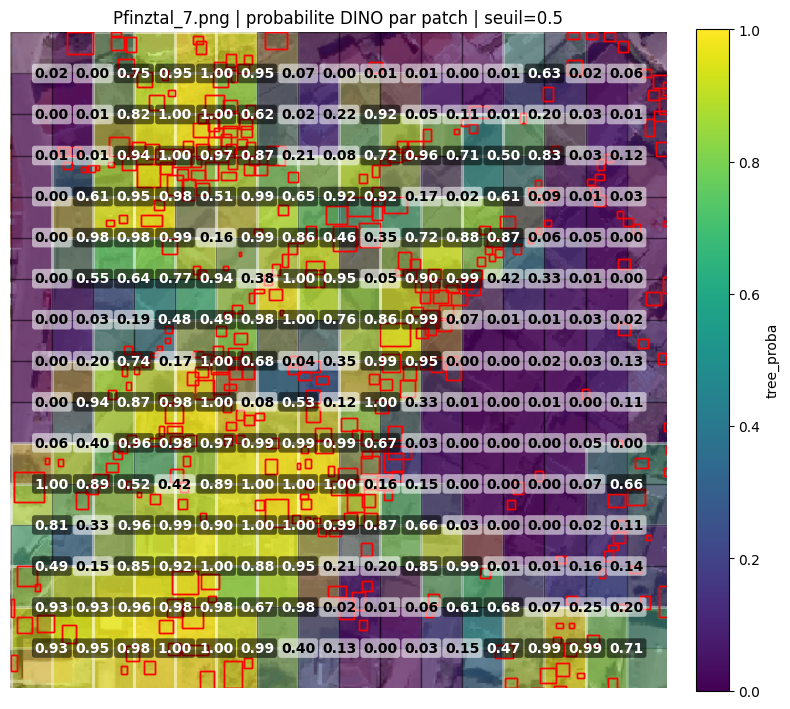

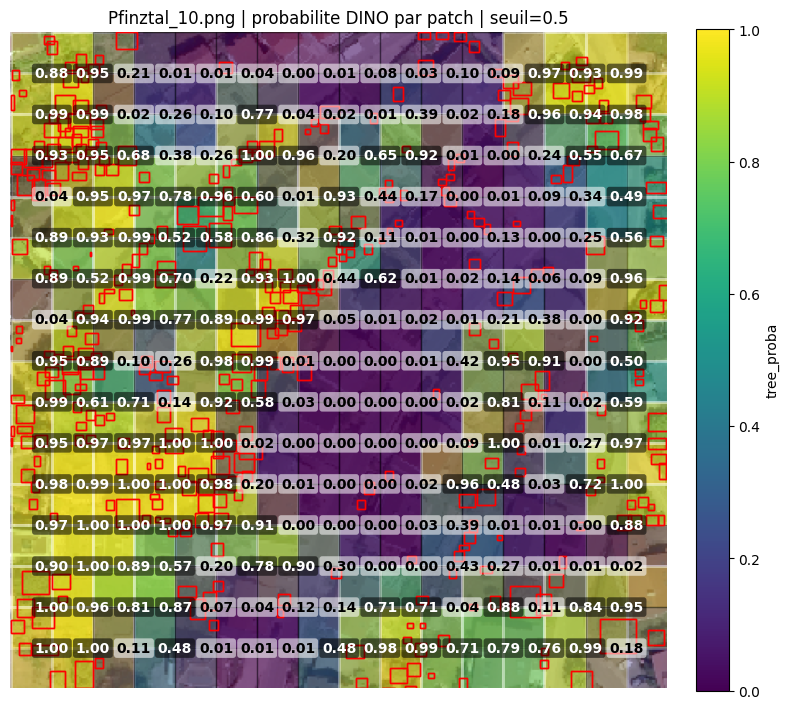

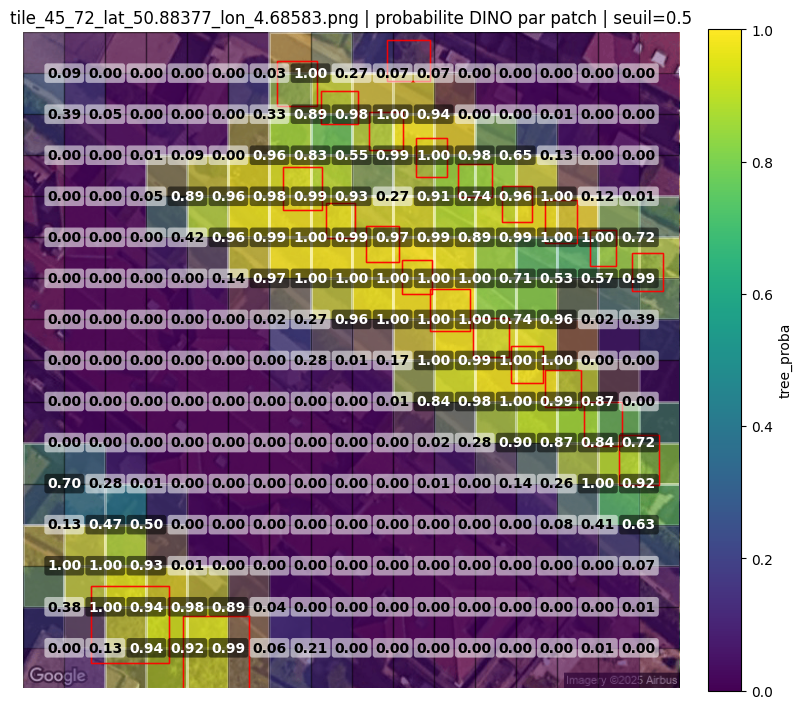

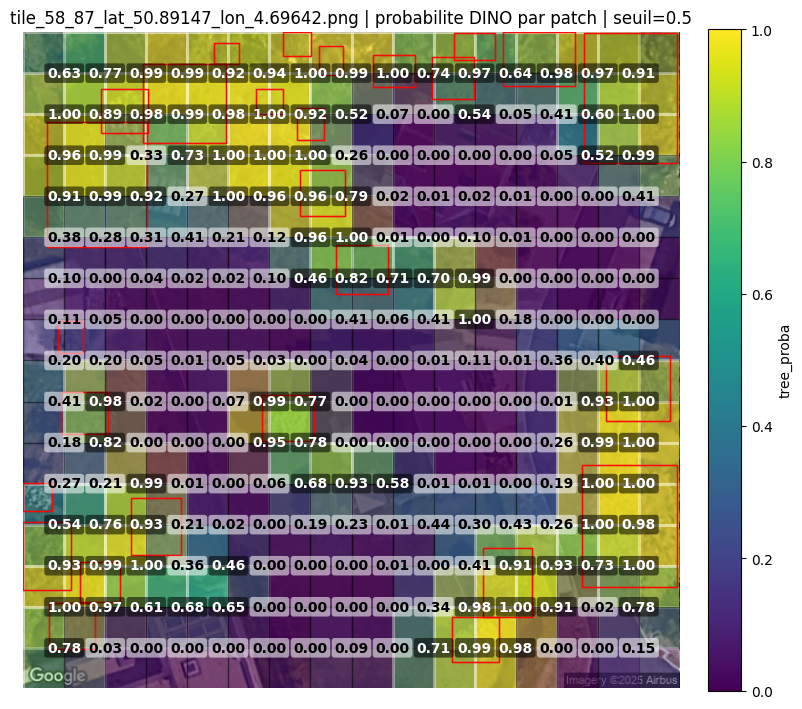

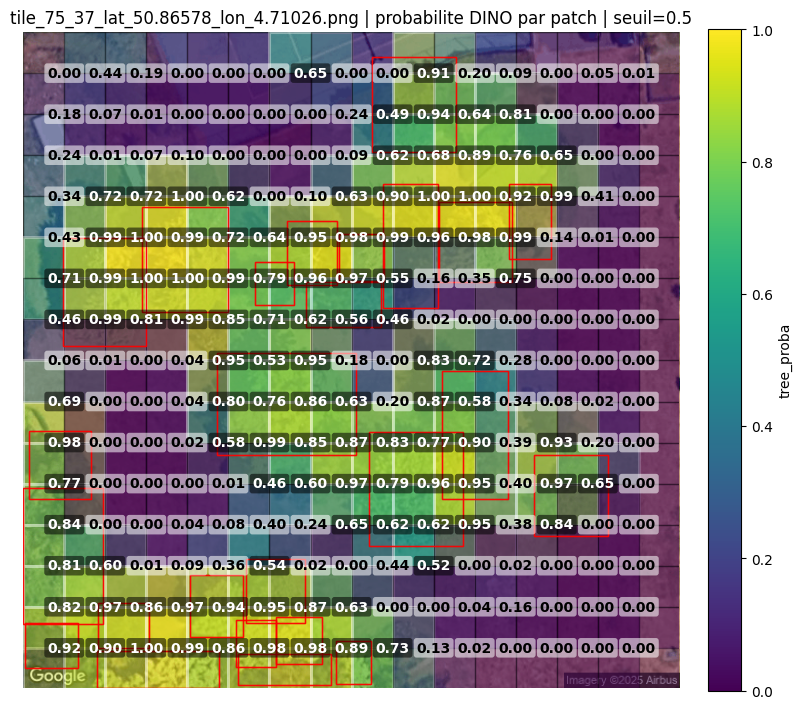

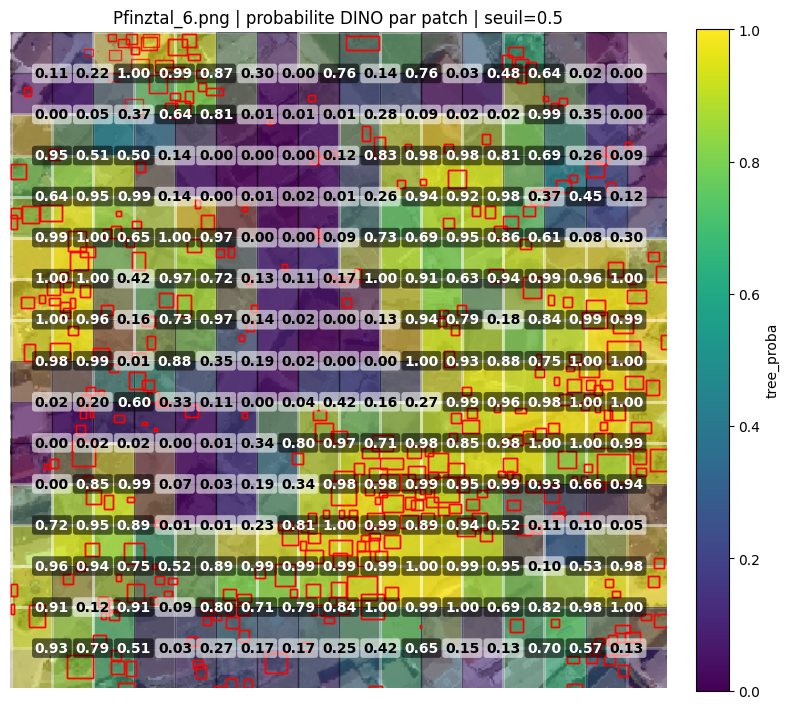

In [22]:
for filename in dino_pred_df["filename"].unique():
    show_patch_probabilities_on_image(
        filename,
        dino_pred_df,
        threshold=0.5,
        show_gt=True,
        show_values=False,
    )


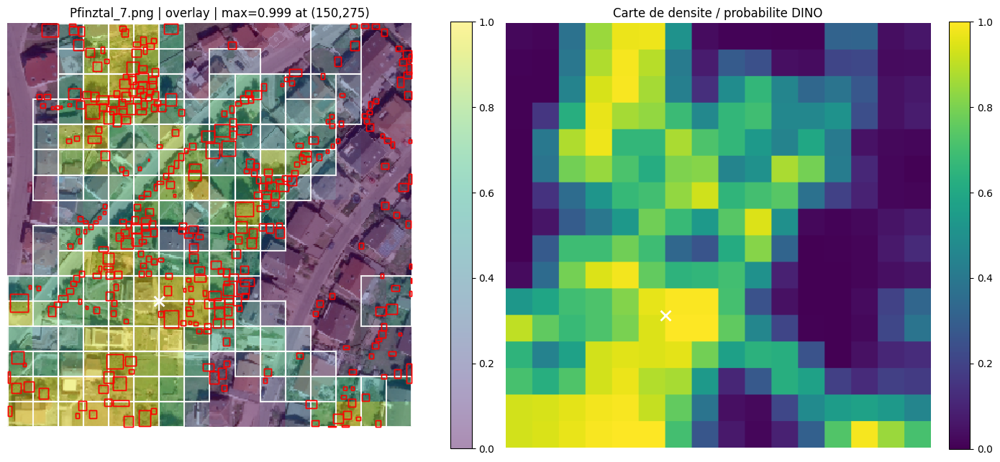

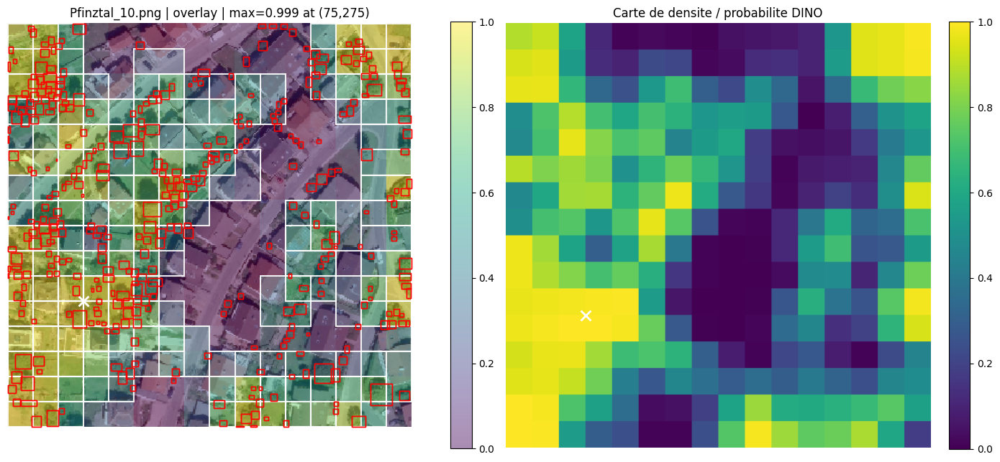

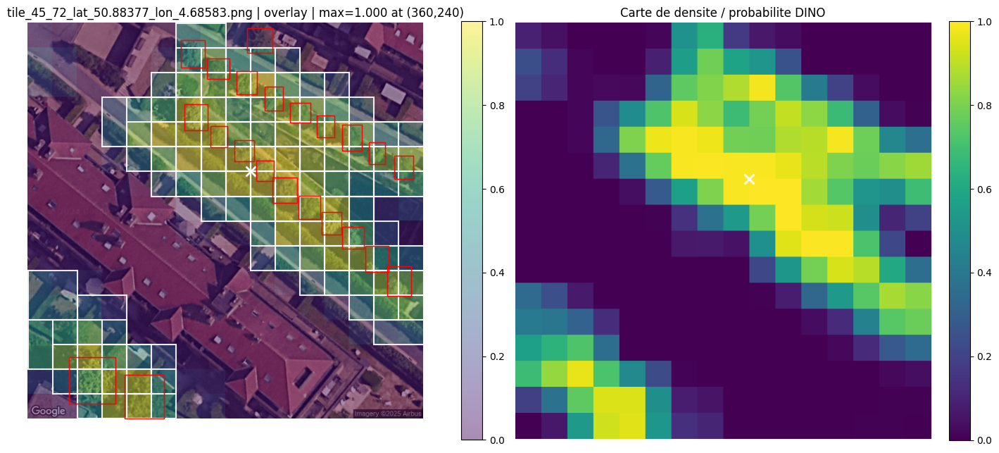

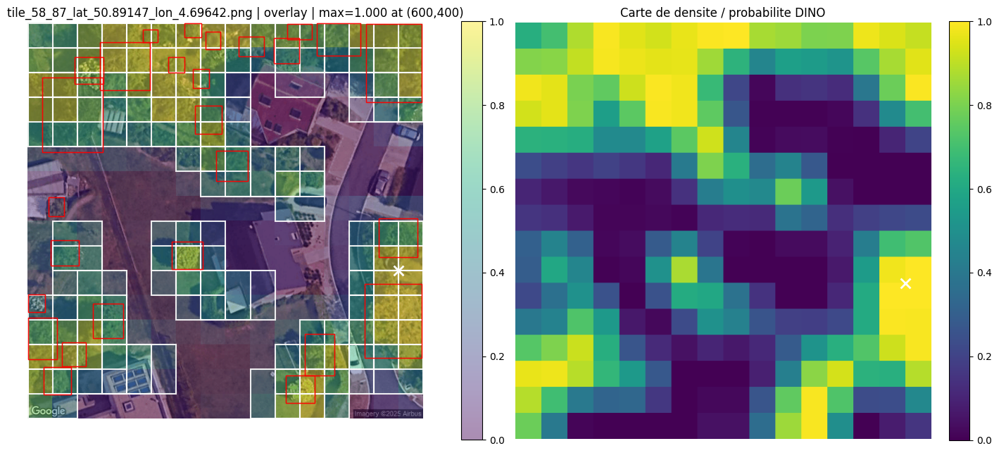

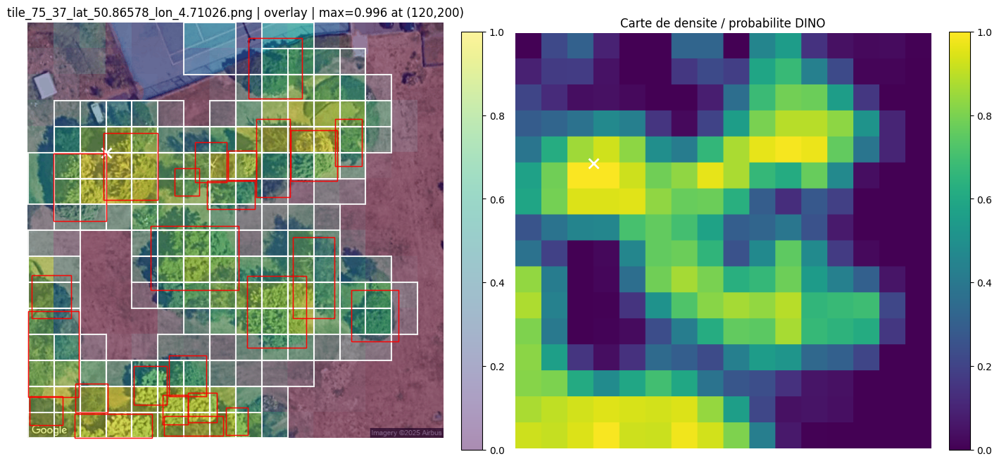

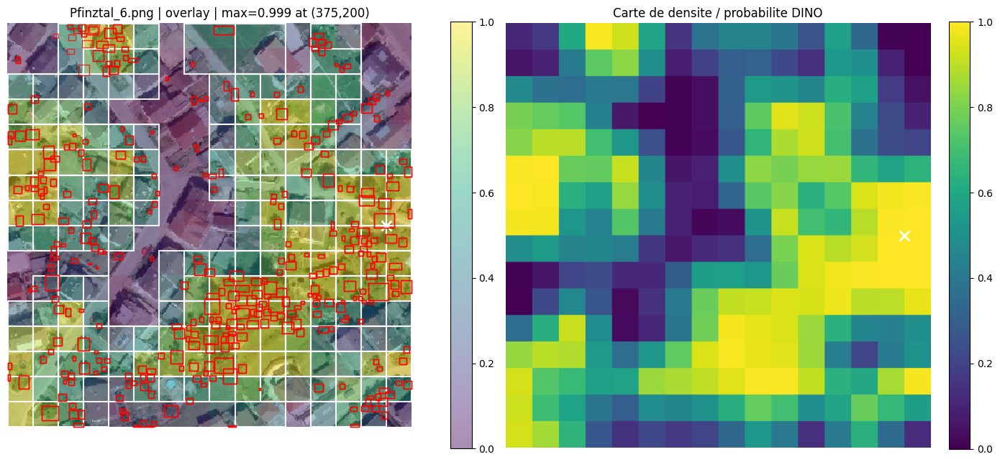

In [23]:
for filename in dino_pred_df["filename"].unique():
    _ = show_probability_map(
        filename,
        dino_pred_df,
        threshold=0.5,
        show_gt=True,
        show_positive_patches=True,
    )


In [ ]:
if DINO_08_DENSITY_INDEX.exists():
    density_maps_index = pd.read_csv(DINO_08_DENSITY_INDEX)
    display(density_maps_index)


## Generation grille 16 x 16 avec stride 50%

Cette cellule rappelle les chemins de la grille 16 x 16 corrigee : 31 positions par ligne, donc 961 patches par image. L'inference DINO correspondante est sauvegardee dans `results/dinov2_model_08_grid16_stride50`.


In [34]:
GRID16 = 16
GRID16_PATCHES_ROOT = LOW_DIR / "patches_grid16_stride50"
GRID16_PATCH_INDEX_CSV = LOW_DIR / "patch_index_grid16_stride50.csv"
GRID16_RESULTS_DIR = RESULTS_DIR / "dinov2_model_08_grid16_stride50"

print("Patches 16x16 stride50:", GRID16_PATCHES_ROOT)
print("Patch index 16x16 stride50:", GRID16_PATCH_INDEX_CSV)
print("Results 16x16 stride50:", GRID16_RESULTS_DIR)

# Les fichiers ont deja ete generes dans ce projet.
# Pour relancer depuis le terminal :
# python3 dino_classif_evaluation.py \
#   --patch-index data/low_density/patch_index_grid16_stride50.csv \
#   --output-dir data/low_density/results/dinov2_model_08_grid16_stride50


Patches 16x16 stride50: data/low_density/patches_grid16_stride50
Patch index 16x16 stride50: data/low_density/patch_index_grid16_stride50.csv
Results 16x16 stride50: data/low_density/results/dinov2_model_08_grid16_stride50


## Rappel architecture DINO classif

Le modele utilise ici est celui du notebook 08 : `dinov2_vits14` comme backbone feature extractor, puis une petite tete MLP binaire. Le backbone sort un vecteur de dimension 384 par image/patch. La tete fait `Linear(384, 128) -> ReLU -> Dropout(0.2) -> Linear(128, 2)`.

Pendant l'entrainement du modele 08, le backbone DINO est gele et seule la tete de classification est entrainee. En inference, on applique `softmax(logits, dim=1)[:, 1]` pour obtenir `tree_proba`, la probabilite du patch positif / arbre.


## Comparaison des trois tailles de patches avec stride 50%

On compare ici les trois decoupages corriges :

- grille nominale 4 x 4 avec stride 50% : 7 x 7 patches par image
- grille nominale 8 x 8 avec stride 50% : 15 x 15 patches par image
- grille nominale 16 x 16 avec stride 50% : 31 x 31 patches par image

Pour chaque version, on affiche un `classification_report`, un resume des probas par image, la densite patch par patch sur l'image originale, puis la carte de densite agregee au max.


In [46]:
from sklearn.metrics import classification_report, confusion_matrix

PATCH_EVALS = {
    "grid4_stride50": {
        "label": "Grille 4x4 stride50",
        "pred_csv": RESULTS_DIR / "dinov2_model_08_grid4_stride50" / "dino_model_08_low_density_predictions.csv",
        "density_index": RESULTS_DIR / "dinov2_model_08_grid4_stride50" / "density_maps" / "density_maps_index.csv",
    },
    "grid8_stride50": {
        "label": "Grille 8x8 stride50",
        "pred_csv": RESULTS_DIR / "dinov2_model_08_grid8_stride50" / "dino_model_08_low_density_predictions.csv",
        "density_index": RESULTS_DIR / "dinov2_model_08_grid8_stride50" / "density_maps" / "density_maps_index.csv",
    },
    "grid16_stride50": {
        "label": "Grille 16x16 stride50",
        "pred_csv": RESULTS_DIR / "dinov2_model_08_grid16_stride50" / "dino_model_08_low_density_predictions.csv",
        "density_index": RESULTS_DIR / "dinov2_model_08_grid16_stride50" / "density_maps" / "density_maps_index.csv",
    },
}

patch_eval_dfs = {}
for key, cfg in PATCH_EVALS.items():
    df = pd.read_csv(cfg["pred_csv"])
    df["pred_label"] = (df["tree_proba"] >= 0.5).astype(int)
    patch_eval_dfs[key] = df
    print(key, "->", len(df), "patches", "|", cfg["pred_csv"])


grid4_stride50 -> 294 patches | data/low_density/results/dinov2_model_08_grid4_stride50/dino_model_08_low_density_predictions.csv
grid8_stride50 -> 1350 patches | data/low_density/results/dinov2_model_08_grid8_stride50/dino_model_08_low_density_predictions.csv
grid16_stride50 -> 5766 patches | data/low_density/results/dinov2_model_08_grid16_stride50/dino_model_08_low_density_predictions.csv


## Metriques cartes de densite : max vs mean

Les `classification_report` precedents evaluent l'inference patch-level : `patch_label` contre `tree_proba` pour toutes les fenetres balayees. C'est le coeur de l'evaluation du classifieur.

Ici on ajoute une evaluation pixel-level des cartes de densite obtenues apres reprojection des patches sur l'image originale. On compare deux aggregations des patches chevauchants :

- `max` : chaque pixel prend la plus forte proba des patches qui le couvrent
- `mean` : chaque pixel prend la moyenne des probas des patches qui le couvrent

Les bbox GT sont rasterisees en masque binaire pixel-level pour calculer les metriques avec `pipeline.compute_binary_metrics`.


In [47]:
def build_probability_map_mean(df_one_image):

    W = int(df_one_image["image_width"].iloc[0])
    H = int(df_one_image["image_height"].iloc[0])

    prob_sum = np.zeros((H, W), dtype=np.float32)
    count_map = np.zeros((H, W), dtype=np.float32)

    for _, row in df_one_image.iterrows():

        x = int(row["x"])
        y = int(row["y"])
        ps = int(row["patch_size"])
        proba = float(row["tree_proba"])

        x2 = min(x + ps, W)
        y2 = min(y + ps, H)

        prob_sum[y:y2, x:x2] += proba
        count_map[y:y2, x:x2] += 1

    return prob_sum / np.maximum(count_map, 1)


def build_gt_mask(filename, width, height):

    mask = np.zeros((height, width), dtype=np.uint8)
    gt_rows = low_density_df[
        low_density_df["filename"] == filename
    ]

    for _, row in gt_rows.iterrows():
        xmin, ymin, xmax, ymax = map(
            float,
            [row["xmin"], row["ymin"], row["xmax"], row["ymax"]]
        )

        x1 = max(0, int(np.floor(xmin)))
        y1 = max(0, int(np.floor(ymin)))
        x2 = min(width, int(np.ceil(xmax)))
        y2 = min(height, int(np.ceil(ymax)))

        if x2 > x1 and y2 > y1:
            mask[y1:y2, x1:x2] = 1

    return mask


def get_density_map(df_one_image, aggregation="max"):
    if aggregation == "max":
        return build_probability_map(df_one_image)
    if aggregation == "mean":
        return build_probability_map_mean(df_one_image)
    raise ValueError(f"Unknown aggregation: {aggregation}")


In [48]:
from pipeline import compute_binary_metrics


def density_map_metrics(pred_df, aggregation="max", threshold=0.5):

    rows = []
    all_true = []
    all_prob = []

    for filename, one in pred_df.groupby("filename"):
        W = int(one["image_width"].iloc[0])
        H = int(one["image_height"].iloc[0])

        prob_map = get_density_map(one, aggregation=aggregation)
        gt_mask = build_gt_mask(filename, W, H)

        y_true = gt_mask.ravel().astype(int)
        y_prob = prob_map.ravel().astype(float)

        metrics = compute_binary_metrics(
            y_true,
            y_prob,
            threshold=threshold,
        )

        rows.append({
            "filename": filename,
            "aggregation": aggregation,
            "threshold": threshold,
            **metrics,
        })

        all_true.append(y_true)
        all_prob.append(y_prob)

    global_metrics = compute_binary_metrics(
        np.concatenate(all_true),
        np.concatenate(all_prob),
        threshold=threshold,
    )

    rows.append({
        "filename": "__GLOBAL__",
        "aggregation": aggregation,
        "threshold": threshold,
        **global_metrics,
    })

    return pd.DataFrame(rows)


In [49]:
density_metric_tables = []

for key, cfg in PATCH_EVALS.items():
    pred_df_eval = patch_eval_dfs[key]

    for aggregation in ["max", "mean"]:
        metrics_df = density_map_metrics(
            pred_df_eval,
            aggregation=aggregation,
            threshold=0.5,
        )
        metrics_df.insert(0, "setup", cfg["label"])
        density_metric_tables.append(metrics_df)

all_density_metrics_df = pd.concat(
    density_metric_tables,
    ignore_index=True,
)

cols = [
    "setup",
    "aggregation",
    "threshold",
    "accuracy",
    "balanced_accuracy",
    "precision",
    "recall",
    "f1",
    "auroc",
    "ap",
    "tn",
    "fp",
    "fn",
    "tp",
    "n",
]

display(
    all_density_metrics_df[
        all_density_metrics_df["filename"] == "__GLOBAL__"
    ][cols]
)


,setup,aggregation,threshold,accuracy,balanced_accuracy,precision,recall,f1,auroc,ap,tn,fp,fn,tp,n
6,Grille 4x4 stride50,max,0.5,0.539260,0.678779,0.257216,0.891302,0.399223,0.757263,0.330260,659898,755411,31902,261589,1708800
13,Grille 4x4 stride50,mean,0.5,0.539260,0.678779,0.257216,0.891302,0.399223,0.757263,0.330260,659898,755411,31902,261589,1708800
20,Grille 8x8 stride50,max,0.5,0.705807,0.773613,0.355497,0.876899,0.505901,0.825420,0.398184,948721,466588,36129,257362,1708800
27,Grille 8x8 stride50,mean,0.5,0.705807,0.773613,0.355497,0.876899,0.505901,0.825420,0.398184,948721,466588,36129,257362,1708800
34,Grille 16x16 stride50,max,0.5,0.727073,0.612096,0.298676,0.436957,0.354820,0.735122,0.290522,1114180,301129,165248,128243,1708800
41,Grille 16x16 stride50,mean,0.5,0.727073,0.612096,0.298676,0.436957,0.354820,0.735122,0.290522,1114180,301129,165248,128243,1708800


In [50]:
def show_density_map_on_original(
    filename,
    pred_df,
    aggregation="mean",
    threshold=0.5,
    show_gt=True,
):

    img = np.array(
        Image.open(IMAGES_DIR / filename).convert("RGB")
    )

    one = pred_df[
        pred_df["filename"] == filename
    ].copy()

    prob_map = get_density_map(
        one,
        aggregation=aggregation,
    )

    max_y, max_x = np.unravel_index(
        np.argmax(prob_map),
        prob_map.shape
    )
    max_value = float(prob_map[max_y, max_x])

    fig, ax = plt.subplots(figsize=(8, 8))
    ax.imshow(img)
    im = ax.imshow(
        prob_map,
        alpha=0.45,
        vmin=0,
        vmax=1,
        cmap="viridis",
    )

    ax.scatter(
        [max_x],
        [max_y],
        marker="x",
        s=120,
        color="white",
        linewidths=2.5,
    )

    if show_gt:
        gt_rows = low_density_df[
            low_density_df["filename"] == filename
        ]

        for _, row in gt_rows.iterrows():
            xmin, ymin, xmax, ymax = map(
                float,
                [row["xmin"], row["ymin"], row["xmax"], row["ymax"]]
            )
            rect = patches.Rectangle(
                (xmin, ymin),
                xmax - xmin,
                ymax - ymin,
                linewidth=1,
                edgecolor="red",
                facecolor="none",
                alpha=0.8,
            )
            ax.add_patch(rect)

    ax.set_title(
        f"{filename} | {aggregation} density | max={max_value:.3f} at ({max_x},{max_y})"
    )
    ax.axis("off")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.show()

    return prob_map


Grille 4x4 stride50 - carte de densite MEAN


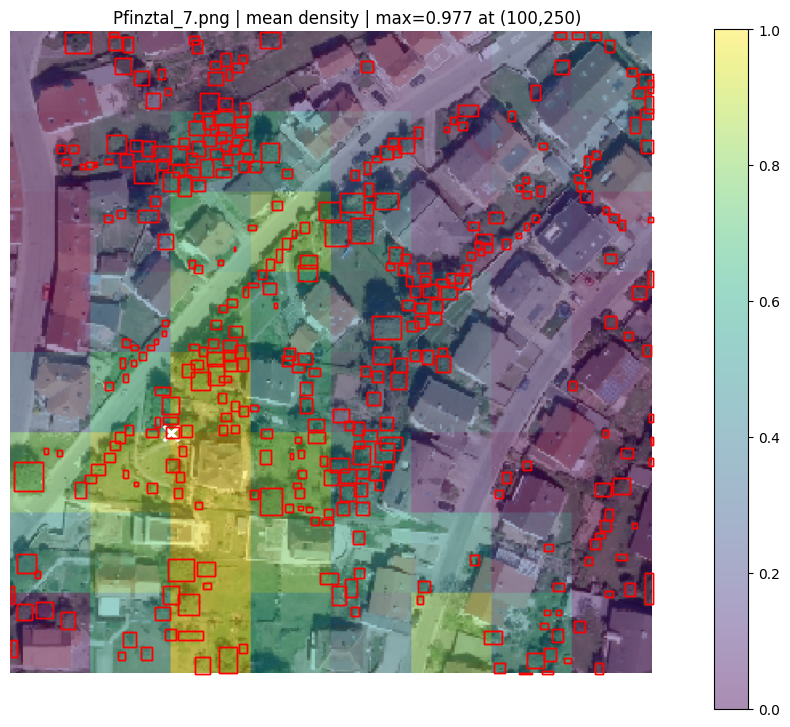

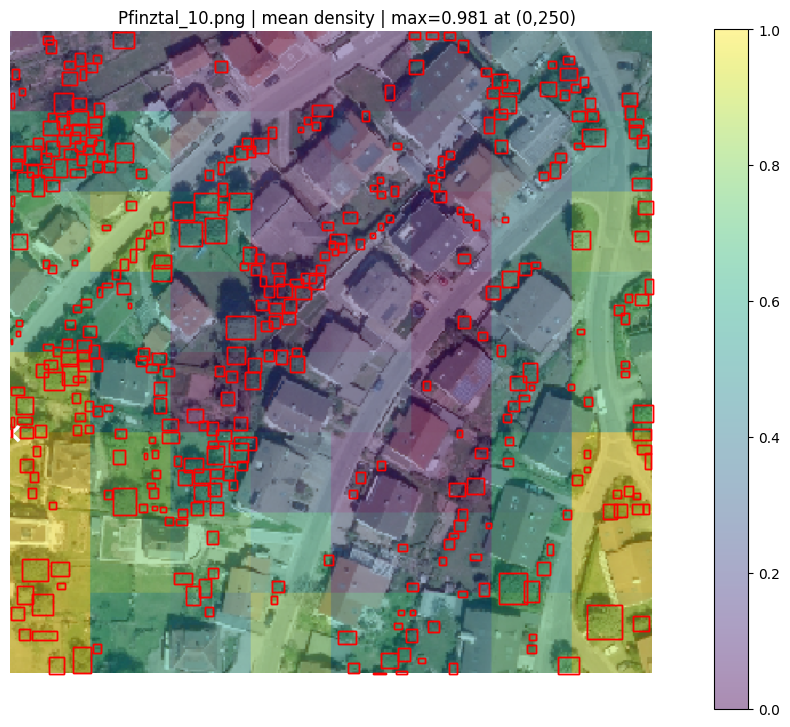

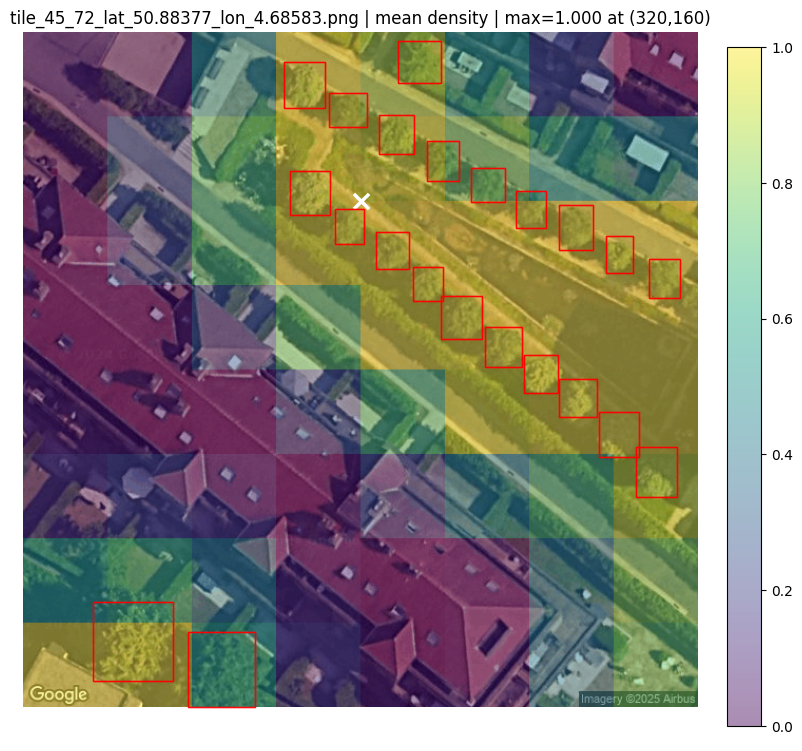

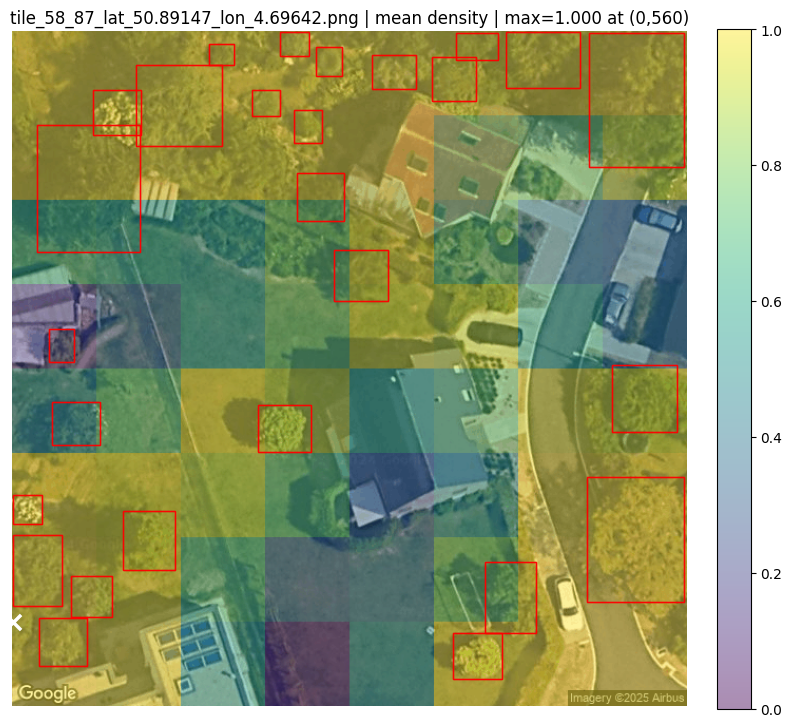

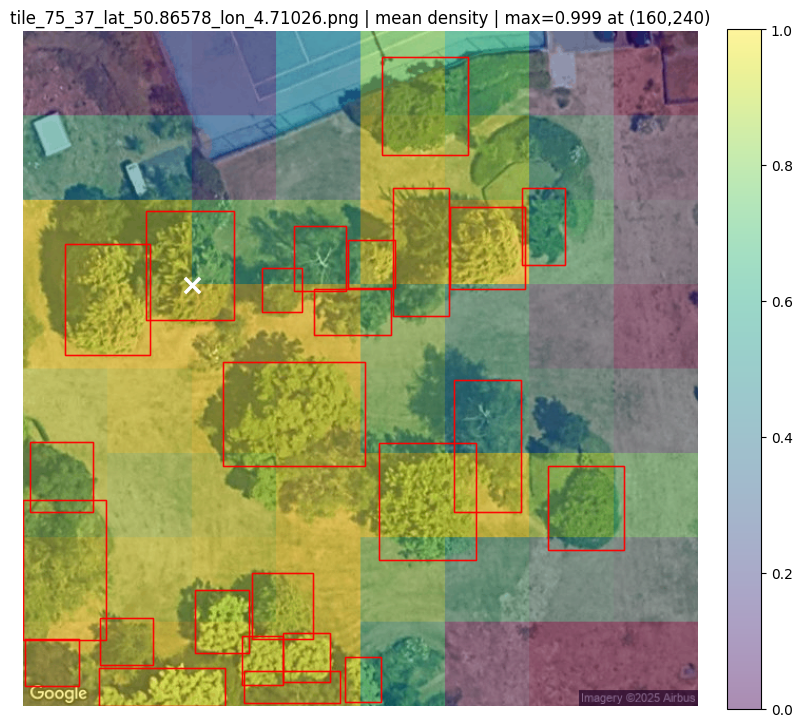

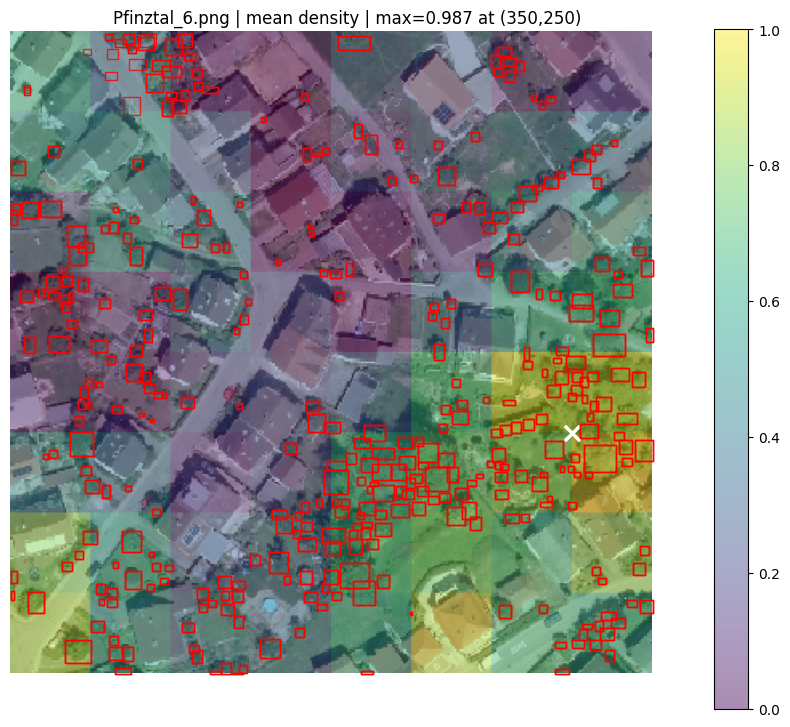

Grille 8x8 stride50 - carte de densite MEAN


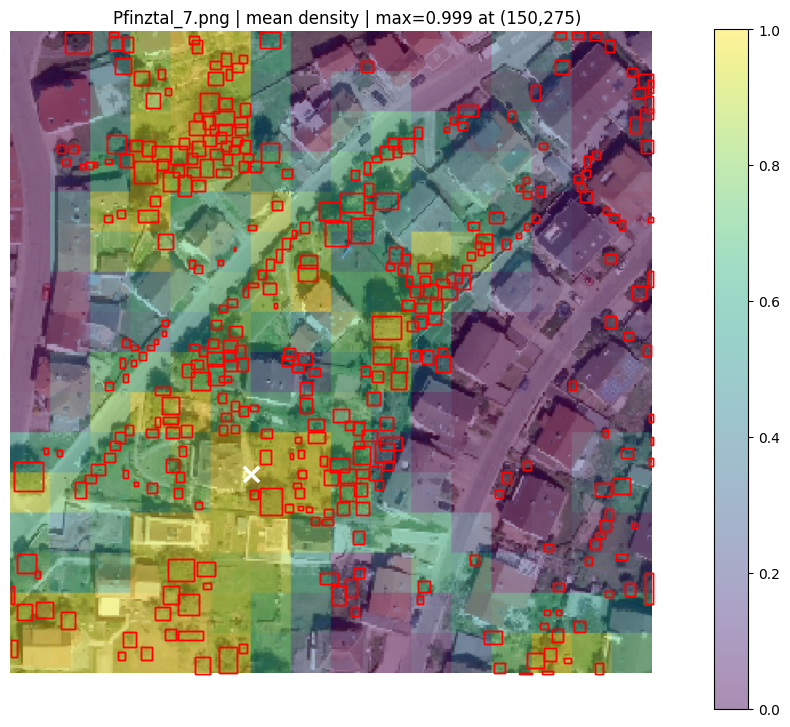

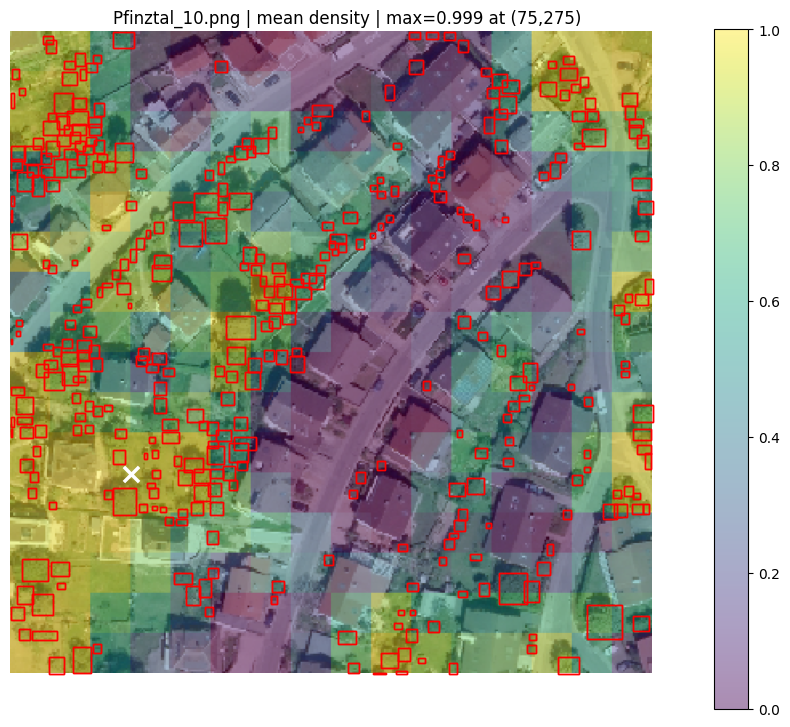

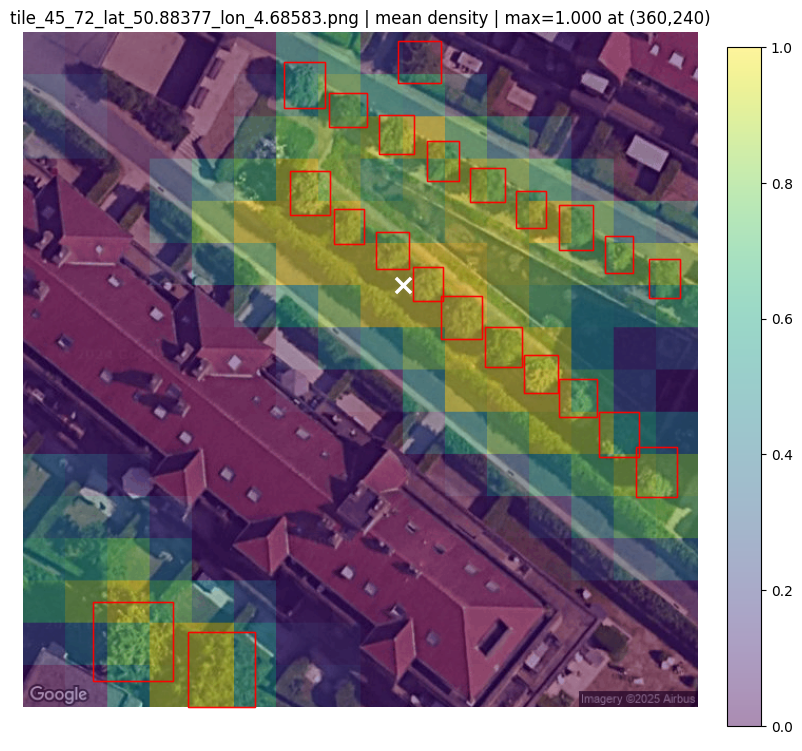

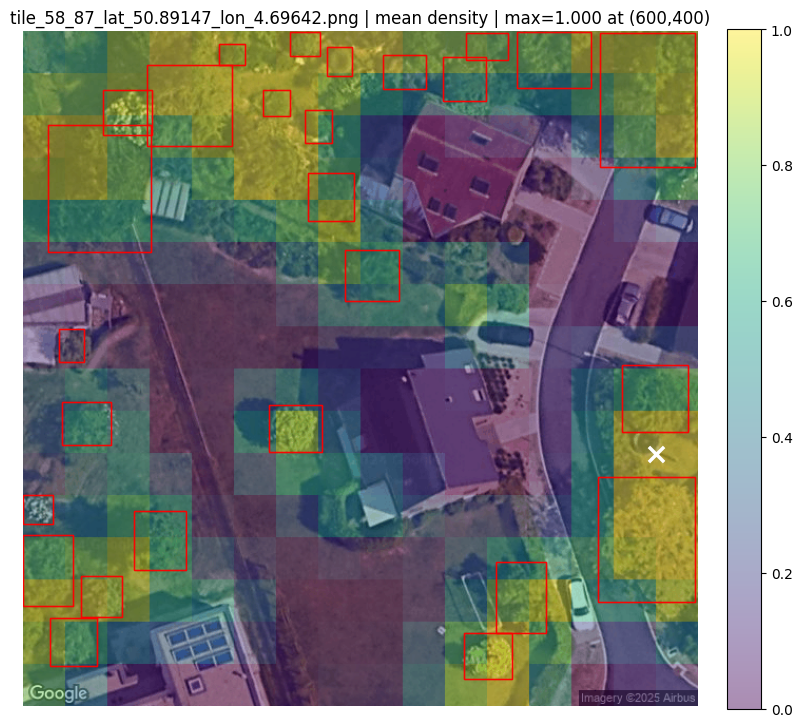

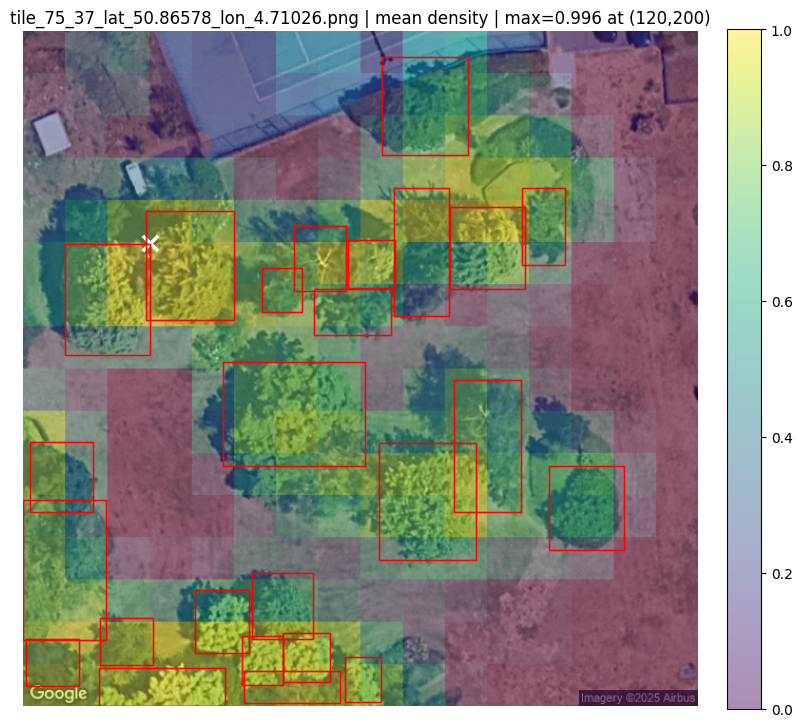

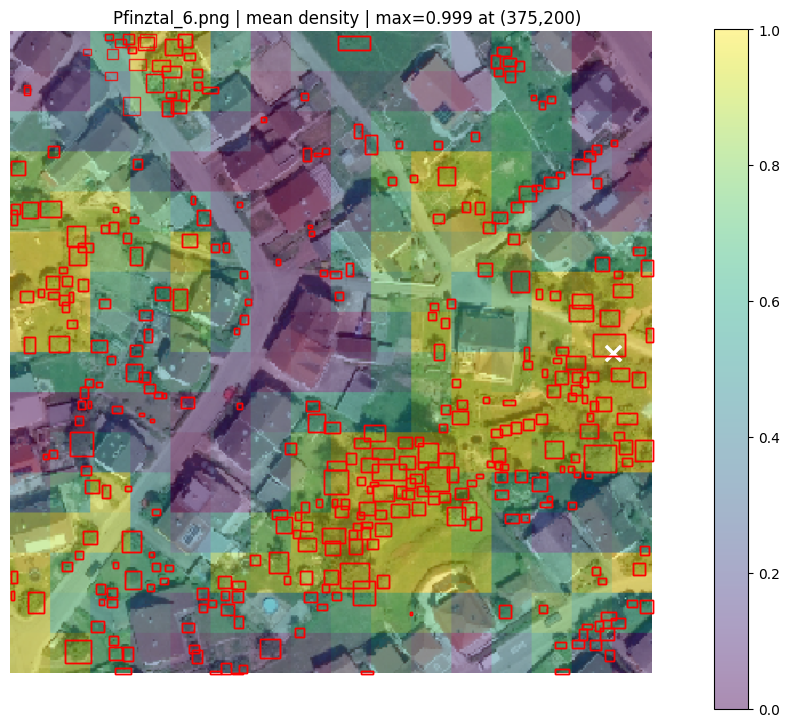

Grille 16x16 stride50 - carte de densite MEAN


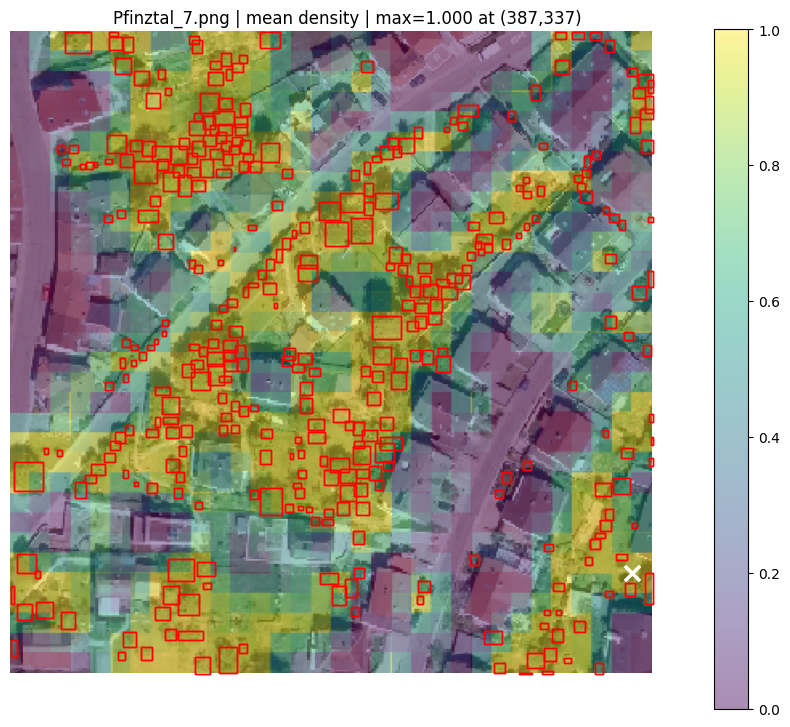

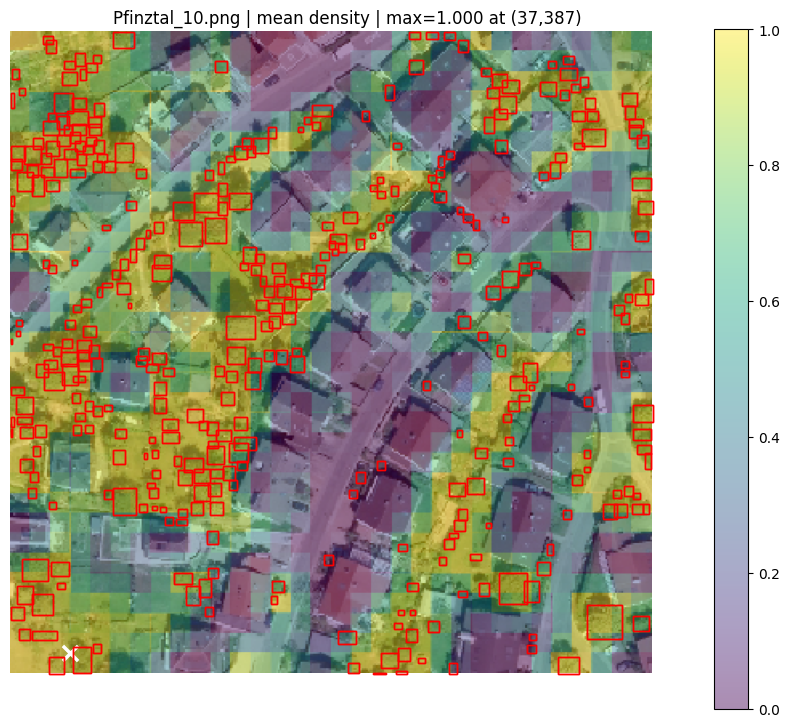

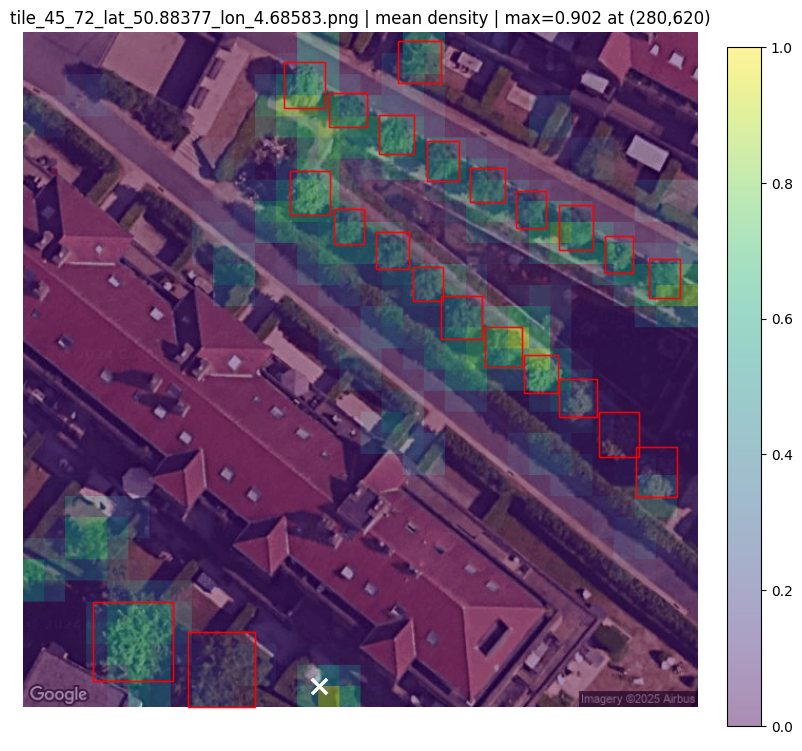

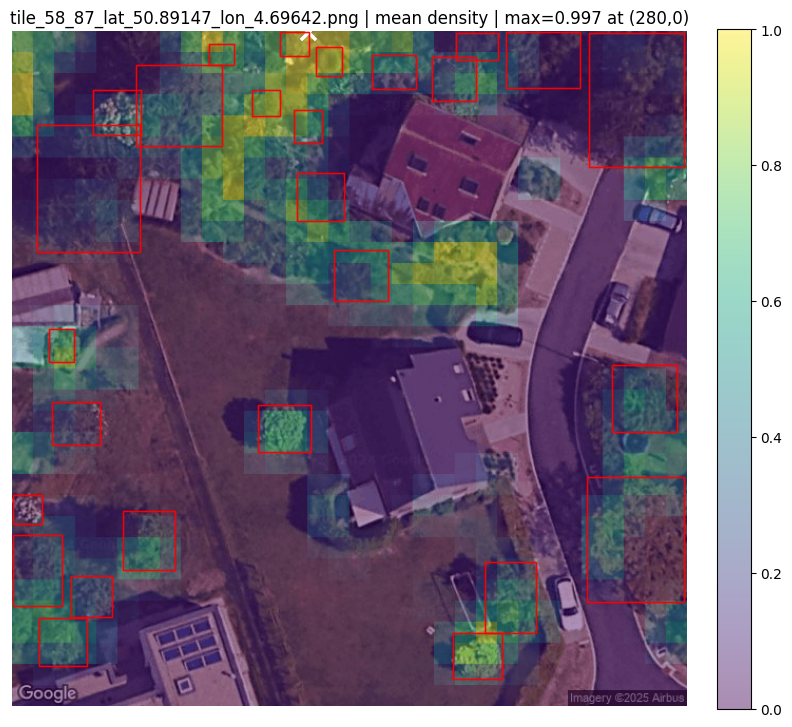

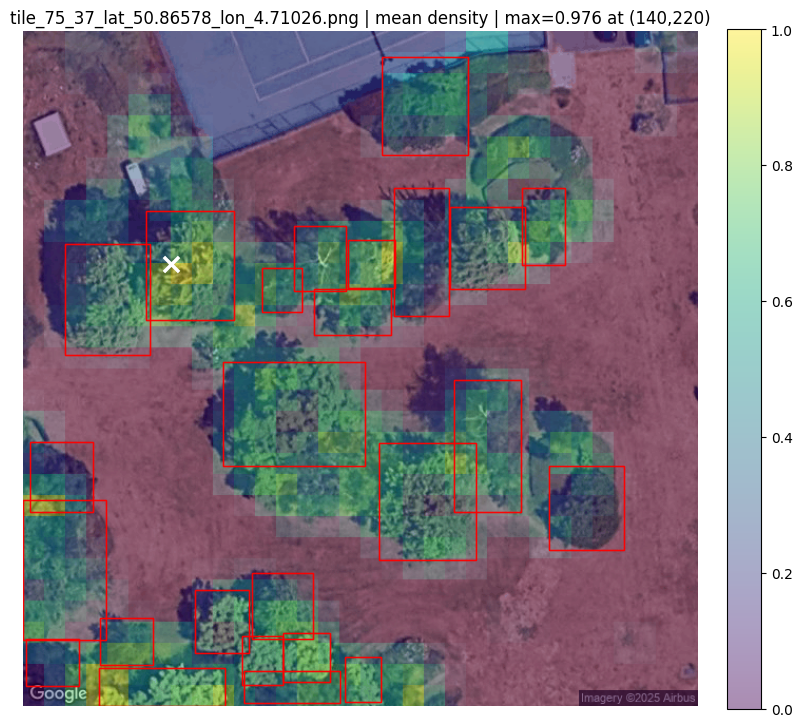

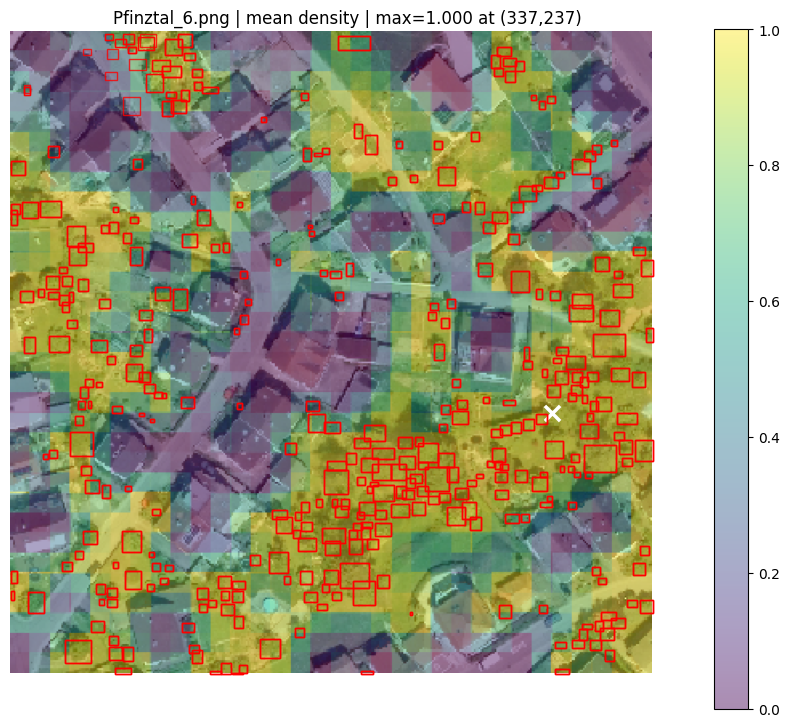

In [51]:
# Version mean  : plotting sur image originale pour les trois balayages
for key, cfg in PATCH_EVALS.items():
    pred_df_eval = patch_eval_dfs[key]
    print("=" * 80)
    print(cfg["label"], "- carte de densite MEAN")

    for filename in pred_df_eval["filename"].unique():
        _ = show_density_map_on_original(
            filename,
            pred_df_eval,
            aggregation="mean",
            threshold=0.5,
            show_gt=True,
        )


In [54]:
def classification_report_df(pred_df, threshold=0.5):
    y_true = pred_df["patch_label"].astype(int).values
    y_pred = (pred_df["tree_proba"].astype(float).values >= threshold).astype(int)

    report = classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["no_tree_patch", "tree_patch"],
        zero_division=0,
        output_dict=True,
    )

    return pd.DataFrame(report).T


def confusion_matrix_df(pred_df, threshold=0.5):
    y_true = pred_df["patch_label"].astype(int).values
    y_pred = (pred_df["tree_proba"].astype(float).values >= threshold).astype(int)
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    return pd.DataFrame(
        cm,
        index=["true_no_tree", "true_tree"],
        columns=["pred_no_tree", "pred_tree"],
    )


In [55]:
for key, cfg in PATCH_EVALS.items():
    print("=" * 80)
    print(cfg["label"])
    pred_df_eval = patch_eval_dfs[key]

    display(classification_report_df(pred_df_eval, threshold=0.5))
    display(confusion_matrix_df(pred_df_eval, threshold=0.5))


Grille 4x4 stride50


,precision,recall,f1-score,support
no_tree_patch,0.183099,0.838710,0.300578,31.000000
tree_patch,0.967105,0.558935,0.708434,263.000000
accuracy,0.588435,0.588435,0.588435,0.588435
macro avg,0.575102,0.698823,0.504506,294.000000
weighted avg,0.884438,0.588435,0.665429,294.000000


,pred_no_tree,pred_tree
true_no_tree,26,5
true_tree,116,147


Grille 8x8 stride50


,precision,recall,f1-score,support
no_tree_patch,0.392663,0.926282,0.551527,312.000000
tree_patch,0.962541,0.569364,0.715496,1038.000000
accuracy,0.651852,0.651852,0.651852,0.651852
macro avg,0.677602,0.747823,0.633512,1350.000000
weighted avg,0.830836,0.651852,0.677601,1350.000000


,pred_no_tree,pred_tree
true_no_tree,289,23
true_tree,447,591


Grille 16x16 stride50


,precision,recall,f1-score,support
no_tree_patch,0.629404,0.883567,0.735137,2568.000000
tree_patch,0.861638,0.582239,0.694906,3198.000000
accuracy,0.716441,0.716441,0.716441,0.716441
macro avg,0.745521,0.732903,0.715021,5766.000000
weighted avg,0.758208,0.716441,0.712823,5766.000000


,pred_no_tree,pred_tree
true_no_tree,2269,299
true_tree,1336,1862


In [56]:
comparison_rows = []

for key, cfg in PATCH_EVALS.items():
    pred_df_eval = patch_eval_dfs[key]

    for filename, one in pred_df_eval.groupby("filename"):
        comparison_rows.append({
            "setup": cfg["label"],
            "filename": filename,
            "n_patches": len(one),
            "patch_size": int(one["patch_size"].iloc[0]),
            "n_gt_positive_patches": int(one["patch_label"].sum()),
            "n_pred_positive_patches": int((one["tree_proba"] >= 0.5).sum()),
            "min_tree_proba": float(one["tree_proba"].min()),
            "mean_tree_proba": float(one["tree_proba"].mean()),
            "max_tree_proba": float(one["tree_proba"].max()),
        })

patch_size_comparison_df = pd.DataFrame(comparison_rows)
display(patch_size_comparison_df)


,setup,filename,n_patches,patch_size,n_gt_positive_patches,n_pred_positive_patches,min_tree_proba,mean_tree_proba,max_tree_proba
0,Grille 4x4 stride50,Pfinztal_10.png,49,100,49,18,1.177408e-02,0.417499,0.985984
1,Grille 4x4 stride50,Pfinztal_6.png,49,100,49,18,3.821498e-03,0.388062,0.993582
2,Grille 4x4 stride50,Pfinztal_7.png,49,100,49,18,5.270660e-03,0.406975,0.986666
3,Grille 4x4 stride50,tile_45_72_lat_50.88377_lon_4.68583.png,49,160,29,25,2.781309e-07,0.519364,0.999990
4,Grille 4x4 stride50,tile_58_87_lat_50.89147_lon_4.69642.png,49,160,42,38,1.369423e-05,0.772110,0.999825
5,Grille 4x4 stride50,tile_75_37_lat_50.86578_lon_4.71026.png,49,160,45,35,5.611726e-06,0.699664,0.999999
6,Grille 8x8 stride50,Pfinztal_10.png,225,50,219,108,5.693766e-05,0.477425,0.999915
7,Grille 8x8 stride50,Pfinztal_6.png,225,50,216,128,1.024927e-04,0.556597,0.999986
8,Grille 8x8 stride50,Pfinztal_7.png,225,50,210,109,1.072354e-05,0.479014,0.999965
9,Grille 8x8 stride50,tile_45_72_lat_50.88377_lon_4.68583.png,225,80,91,76,1.916986e-13,0.338192,0.999996


In [59]:
# voir une seule image/echelle ponctuellement, appeler :
# show_patch_probabilities_on_image(filename, pred_df_eval, threshold=0.5)

Grille 4x4 stride50 - carte de densite max


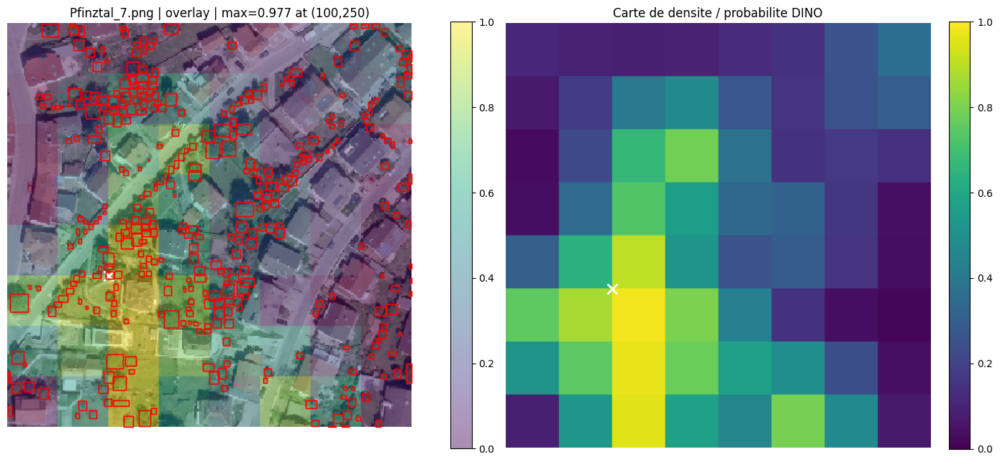

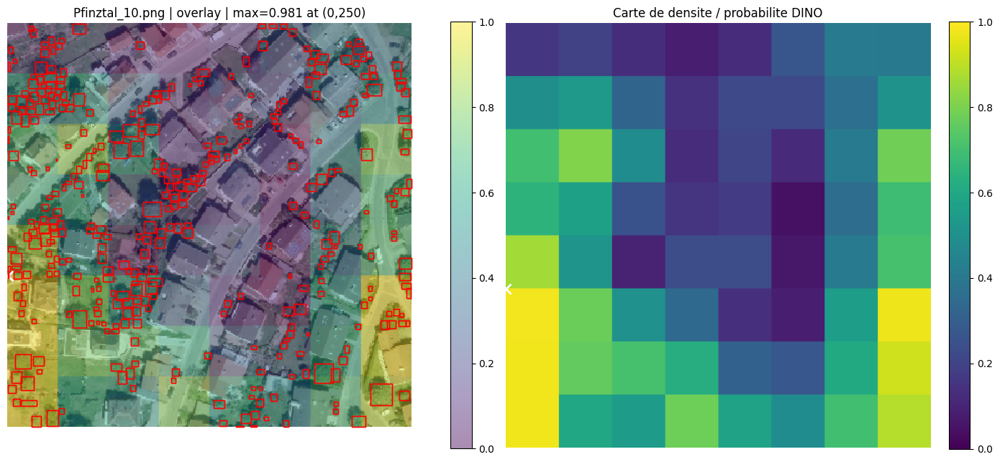

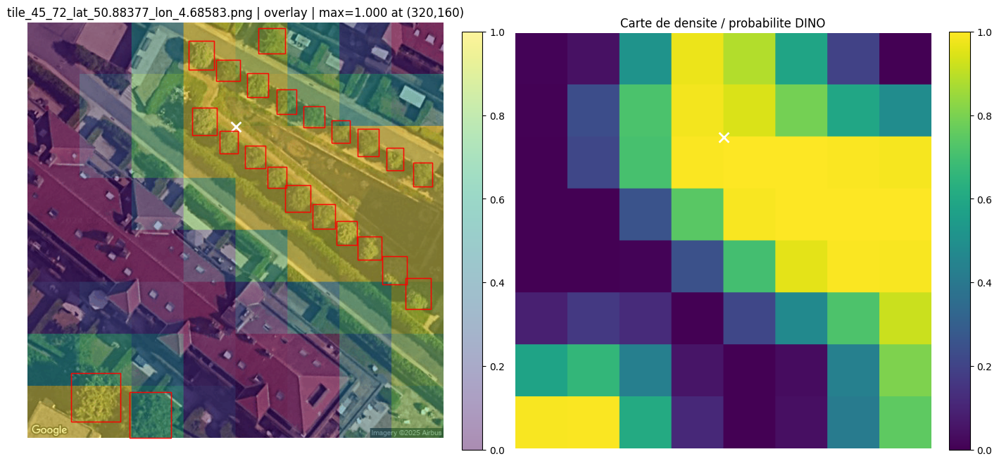

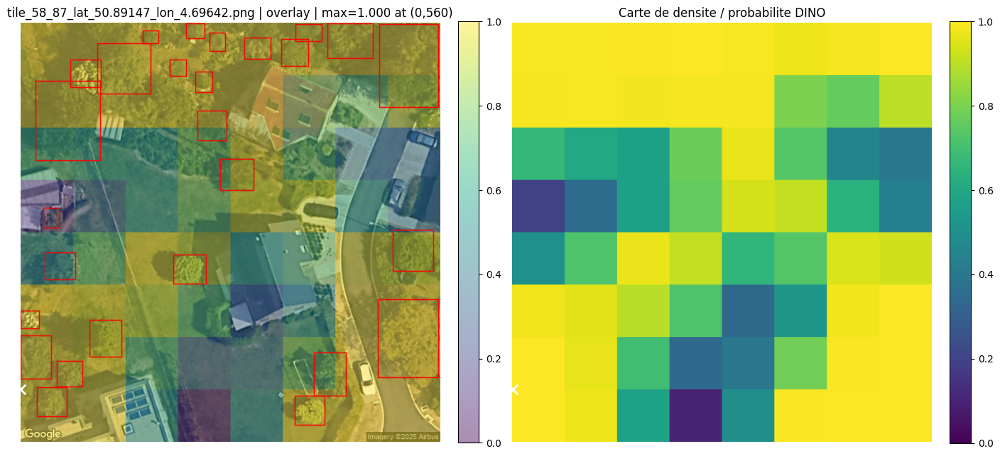

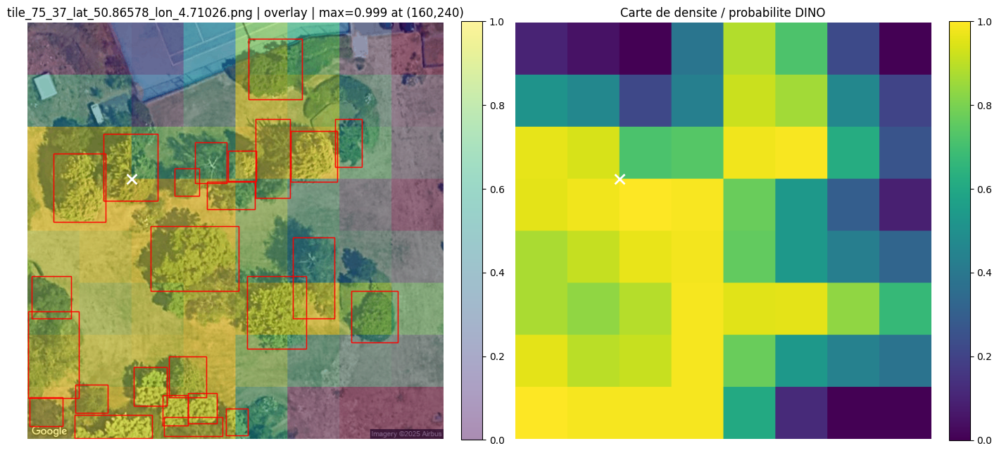

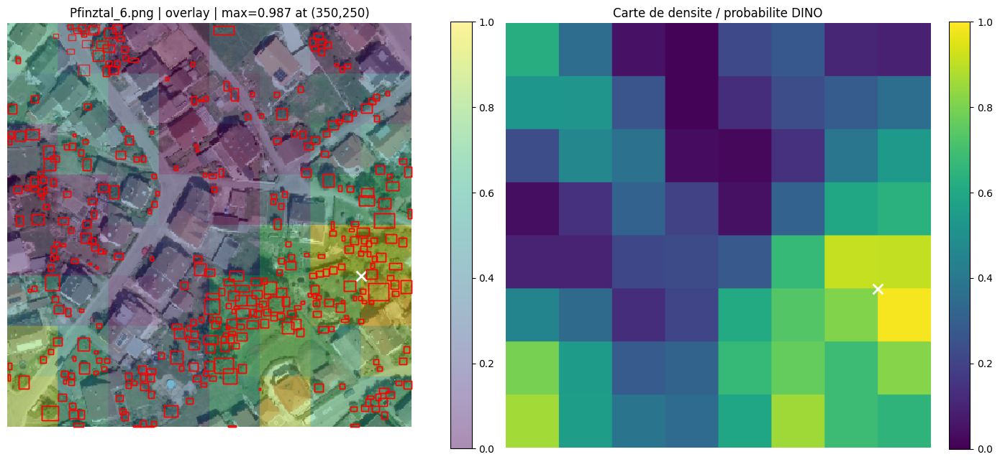

Grille 8x8 stride50 - carte de densite max


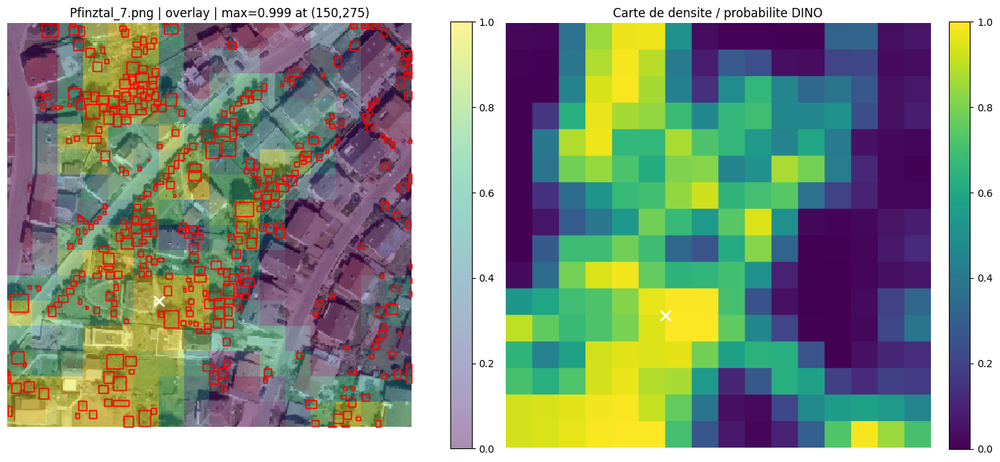

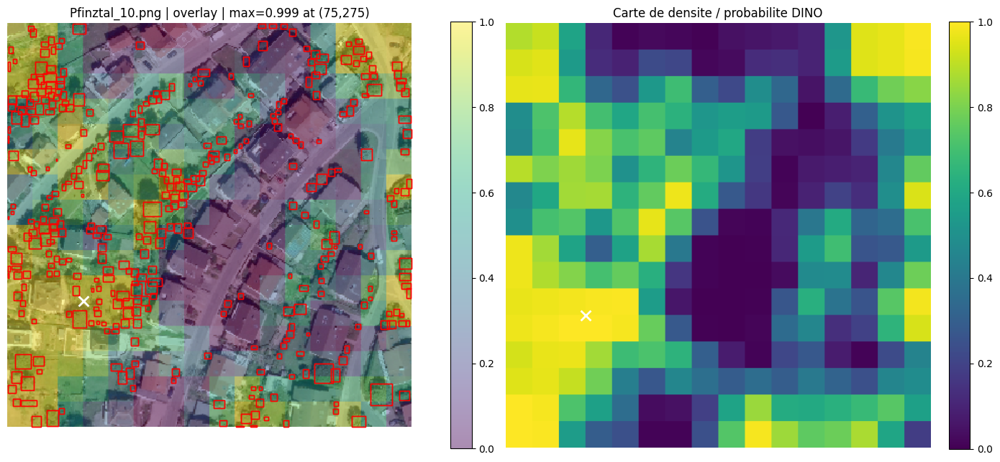

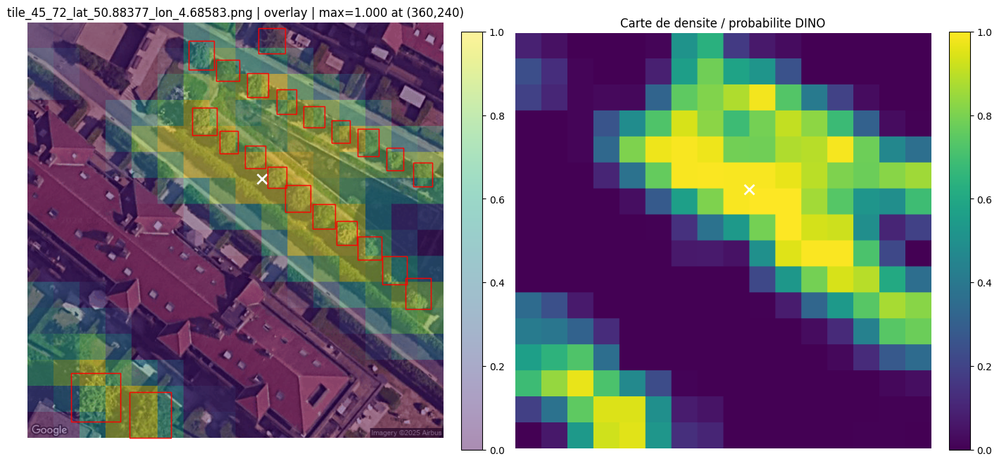

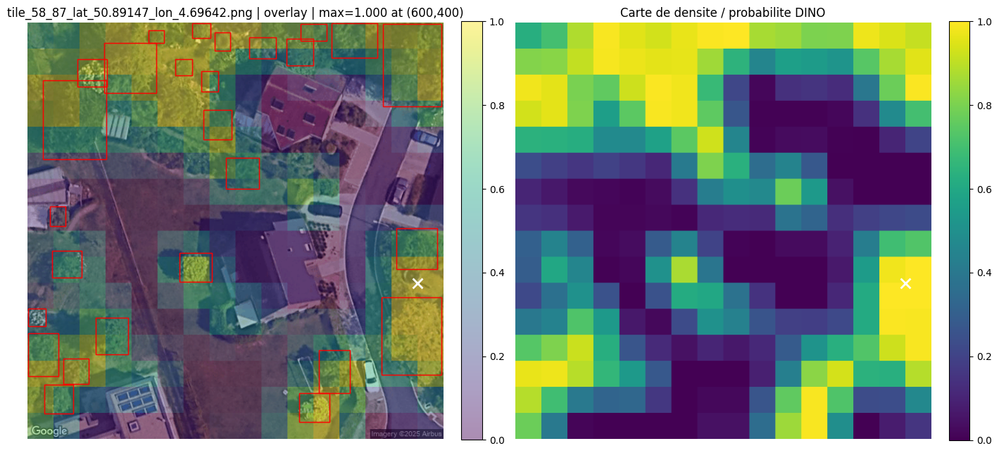

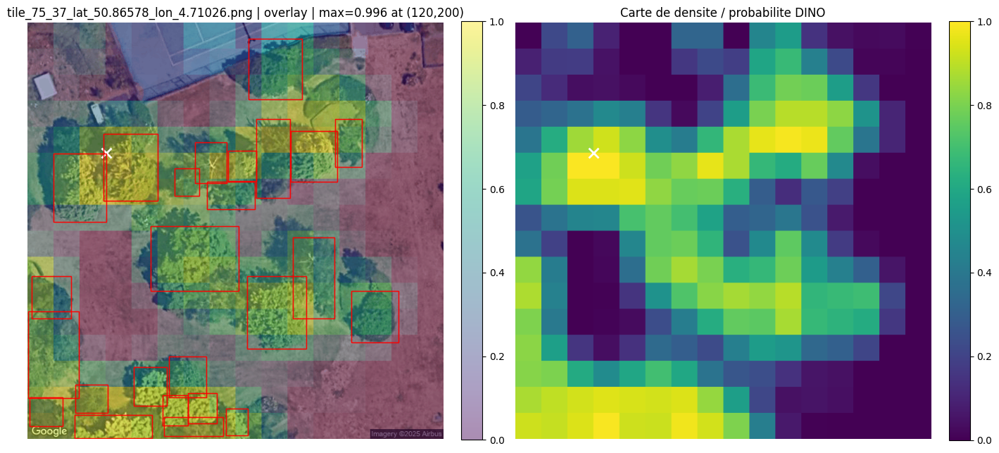

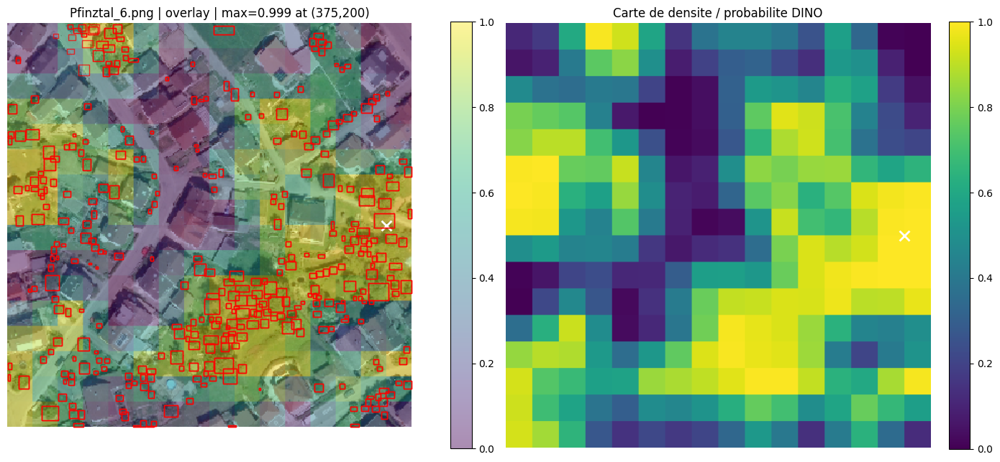

Grille 16x16 stride50 - carte de densite max


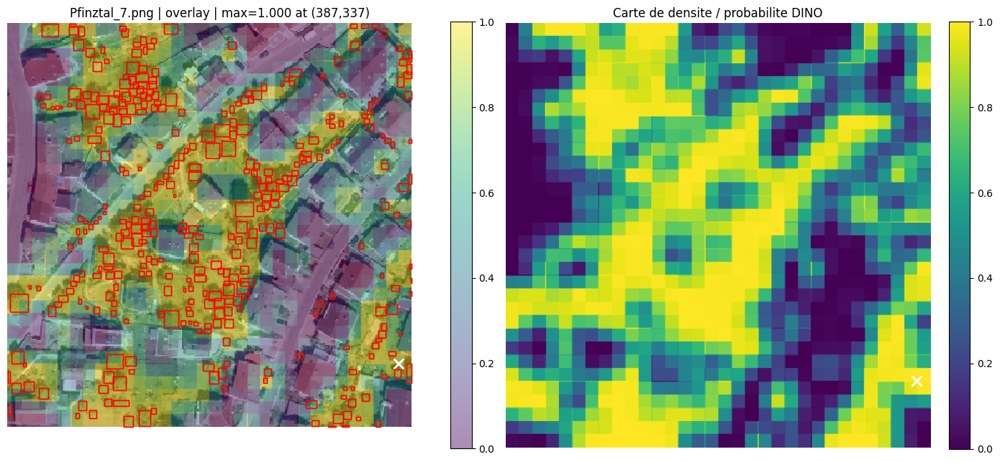

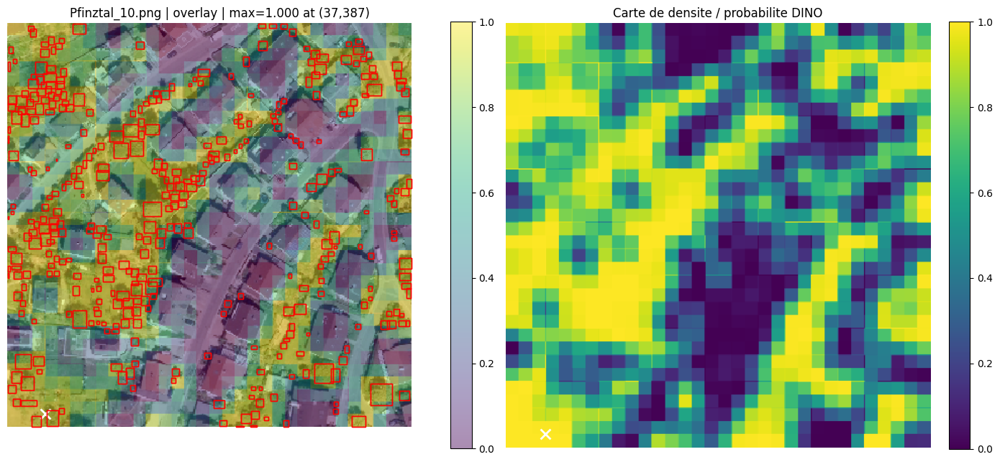

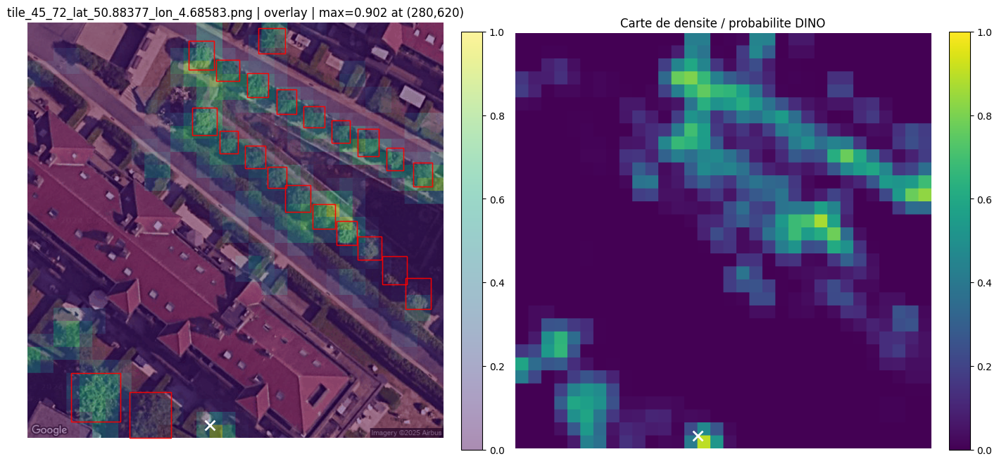

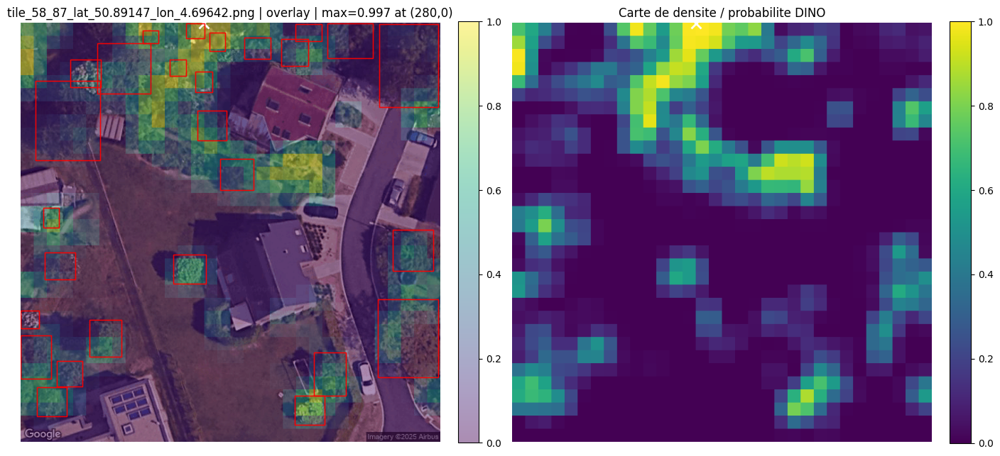

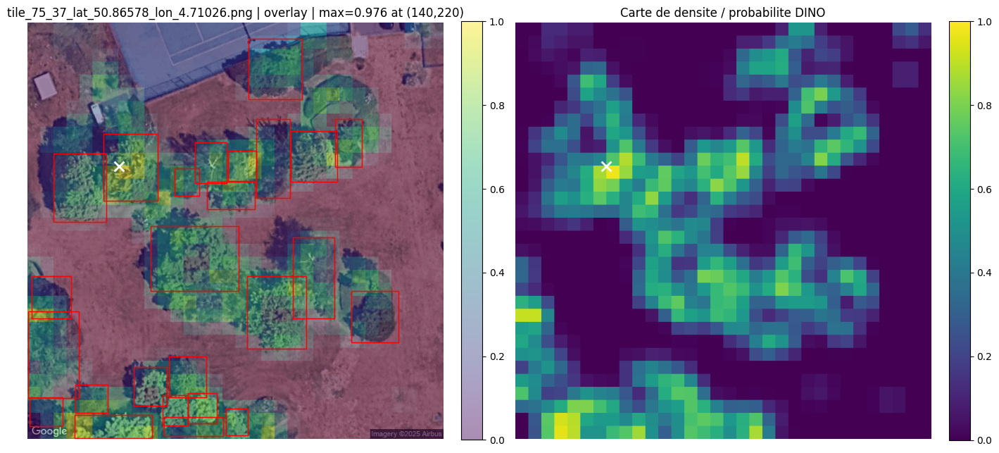

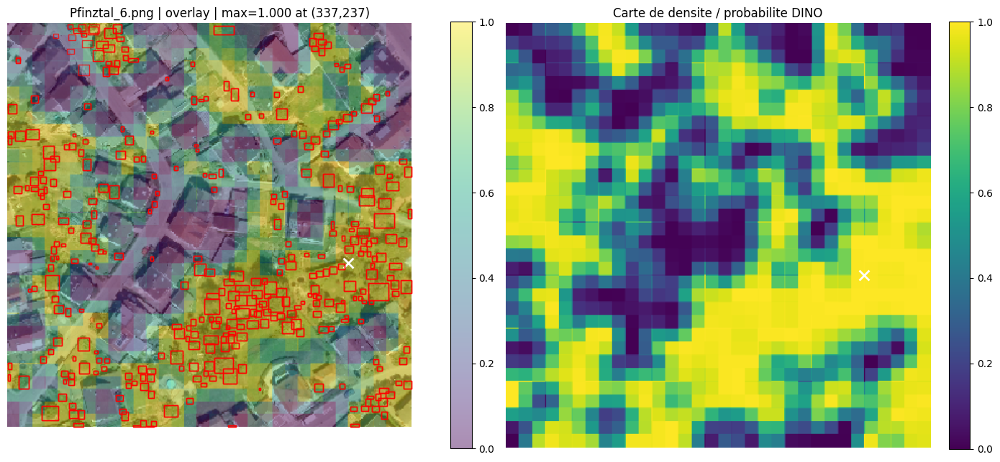

In [58]:
# Affichage cartes de densite agregees au max pour les trois tailles
for key, cfg in PATCH_EVALS.items():
    pred_df_eval = patch_eval_dfs[key]
    print("=" * 80)
    print(cfg["label"], "- carte de densite max")

    for filename in pred_df_eval["filename"].unique():
        _ = show_probability_map(
            filename,
            pred_df_eval,
            threshold=0.5,
            show_gt=True,
            show_positive_patches=False,
        )


In [60]:
for key, cfg in PATCH_EVALS.items():
    if cfg["density_index"].exists():
        print(cfg["label"])
        display(pd.read_csv(cfg["density_index"]))


Grille 4x4 stride50


,filename,probability_map_csv,heatmap_png,overlay_png,map_min,map_mean,map_max,max_x,max_y
0,Pfinztal_10.png,data/low_density/results/dinov2_model_08_grid4...,data/low_density/results/dinov2_model_08_grid4...,data/low_density/results/dinov2_model_08_grid4...,0.109010,0.678051,0.985984,300,200
1,Pfinztal_6.png,data/low_density/results/dinov2_model_08_grid4...,data/low_density/results/dinov2_model_08_grid4...,data/low_density/results/dinov2_model_08_grid4...,0.012826,0.628057,0.993582,200,300
2,Pfinztal_7.png,data/low_density/results/dinov2_model_08_grid4...,data/low_density/results/dinov2_model_08_grid4...,data/low_density/results/dinov2_model_08_grid4...,0.028788,0.573922,0.986666,50,200
3,tile_45_72_lat_50.88377_lon_4.68583.png,data/low_density/results/dinov2_model_08_grid4...,data/low_density/results/dinov2_model_08_grid4...,data/low_density/results/dinov2_model_08_grid4...,0.000021,0.681902,0.999990,240,160
4,tile_58_87_lat_50.89147_lon_4.69642.png,data/low_density/results/dinov2_model_08_grid4...,data/low_density/results/dinov2_model_08_grid4...,data/low_density/results/dinov2_model_08_grid4...,0.199566,0.952704,0.999825,480,320
5,tile_75_37_lat_50.86578_lon_4.71026.png,data/low_density/results/dinov2_model_08_grid4...,data/low_density/results/dinov2_model_08_grid4...,data/low_density/results/dinov2_model_08_grid4...,0.000006,0.826381,0.999999,320,80


Grille 8x8 stride50


,filename,probability_map_csv,heatmap_png,overlay_png,map_min,map_mean,map_max,max_x,max_y
0,Pfinztal_10.png,data/low_density/results/dinov2_model_08_grid8...,data/low_density/results/dinov2_model_08_grid8...,data/low_density/results/dinov2_model_08_grid8...,2.098948e-03,0.725150,0.999915,50,275
1,Pfinztal_6.png,data/low_density/results/dinov2_model_08_grid8...,data/low_density/results/dinov2_model_08_grid8...,data/low_density/results/dinov2_model_08_grid8...,2.277228e-03,0.775808,0.999986,325,225
2,Pfinztal_7.png,data/low_density/results/dinov2_model_08_grid8...,data/low_density/results/dinov2_model_08_grid8...,data/low_density/results/dinov2_model_08_grid8...,1.045784e-04,0.667131,0.999965,125,275
3,tile_45_72_lat_50.88377_lon_4.68583.png,data/low_density/results/dinov2_model_08_grid8...,data/low_density/results/dinov2_model_08_grid8...,data/low_density/results/dinov2_model_08_grid8...,1.741495e-09,0.467438,0.999996,320,200
4,tile_58_87_lat_50.89147_lon_4.69642.png,data/low_density/results/dinov2_model_08_grid8...,data/low_density/results/dinov2_model_08_grid8...,data/low_density/results/dinov2_model_08_grid8...,4.940941e-06,0.633953,0.999911,560,400
5,tile_75_37_lat_50.86578_lon_4.71026.png,data/low_density/results/dinov2_model_08_grid8...,data/low_density/results/dinov2_model_08_grid8...,data/low_density/results/dinov2_model_08_grid8...,1.432933e-09,0.611468,0.999900,120,200


Grille 16x16 stride50


,filename,probability_map_csv,heatmap_png,overlay_png,map_min,map_mean,map_max,max_x,max_y
0,Pfinztal_10.png,data/low_density/results/dinov2_model_08_grid1...,data/low_density/results/dinov2_model_08_grid1...,data/low_density/results/dinov2_model_08_grid1...,6.097849e-06,0.800735,0.999957,38,188
1,Pfinztal_6.png,data/low_density/results/dinov2_model_08_grid1...,data/low_density/results/dinov2_model_08_grid1...,data/low_density/results/dinov2_model_08_grid1...,5.808082e-08,0.808045,0.999968,325,225
2,Pfinztal_7.png,data/low_density/results/dinov2_model_08_grid1...,data/low_density/results/dinov2_model_08_grid1...,data/low_density/results/dinov2_model_08_grid1...,7.562809e-08,0.769198,0.999995,375,325
3,tile_45_72_lat_50.88377_lon_4.68583.png,data/low_density/results/dinov2_model_08_grid1...,data/low_density/results/dinov2_model_08_grid1...,data/low_density/results/dinov2_model_08_grid1...,1.449759e-11,0.212706,0.984848,600,220
4,tile_58_87_lat_50.89147_lon_4.69642.png,data/low_density/results/dinov2_model_08_grid1...,data/low_density/results/dinov2_model_08_grid1...,data/low_density/results/dinov2_model_08_grid1...,2.344163e-12,0.294966,0.999919,280,0
5,tile_75_37_lat_50.86578_lon_4.71026.png,data/low_density/results/dinov2_model_08_grid1...,data/low_density/results/dinov2_model_08_grid1...,data/low_density/results/dinov2_model_08_grid1...,1.362838e-09,0.368436,0.992902,120,220
